<a href="https://colab.research.google.com/github/Melonangie/AcademicPaper/blob/main/modelado2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelado y selección de modelos para predecir la morfología de galaxias MaNGA
### Proceso CRISP-ML(Q): fases de *Modelado* (§3.3) y *Evaluación* (§3.4) — Studer et al. 2021 (arXiv:2003.05155)

**Objetivo.** Predecir la morfología visual de Hubble (T-type) de ~9 900 galaxias MaNGA a partir de su **espectro integrado
en todo el campo de visión (FoV)**. Partimos de:
- `FoV-OUT_features_results`: 51 features físicas medidas sobre `WAVE` y `FLUX_FoV` (en reposo y en vacío), las etiquetas
  y la partición train/test.
- `FoV-OUT_baseline`: el baseline (logística con 10 features) que tenemos que superar.

**Tres esquemas de clases** (los mismos del baseline):
| Esquema | Clases | Regla |
|---|---|---|
| `tres_clases` | Temprana / Intermedia / Tardía | T ≤ 0 / 1 ≤ T ≤ 4 / T ≥ 5 |
| `intervalos` | E, S0–S0a, Sa–Sab, Sb–Sbc, Sc–Sd, Sdm–Im | intervalos de T |
| `detallado` | E, S0, S0a, Sa, Sab, Sb, Sbc, Sc, Scd, Sd, Sdm, Sm, Im | un T-type por clase |

**Mapa de CRISP-ML(Q) → celdas**
| Tarea de CRISP-ML(Q) | Celdas |
|---|---|
| Investigación de literatura sobre problemas similares | 2–3 |
| Definir medidas de calidad del modelo (Tabla 2) y criterios de éxito | 4 |
| Reproducibilidad del método (versiones, semillas, reproducir el baseline) | 5–8, 18–20, 51 |
| Incorporar conocimiento del dominio (espectro en reposo/vacío, orden de las clases, WHAN) | 9–13, 26–28 |
| Entrenamiento: objetivo, regularización, validación cruzada, hiperparámetros | 14–17 |
| Selección de modelo: empezar con baja capacidad y subir paso a paso | 18–25 |
| Datos no etiquetados / representaciones aprendidas (PCA del espectro) | 29–30 |
| Compresión del modelo | 31–32 |
| Métodos de ensamble | 33–34 |
| Reproducibilidad del resultado (media ± σ con varias semillas) | 35–36 |
| Medidas de calidad: robustez, explicabilidad, complejidad, recursos, escalabilidad | 37–39 |
| Selección final del modelo | 40–41 |
| Evaluación: test ciego, análisis por segmentos, explicabilidad, criterios de éxito | 42–50 |
| Documentación experimental | 51 |
| Conclusiones y referencias | 52–53 |

## 1. Morfología de galaxias: qué queremos predecir y por qué el espectro la contiene

### 1.1 La secuencia de Hubble y el T-type
- **Hubble (1926, ApJ 64, 321; 1936, *The Realm of the Nebulae*)** ordenó las galaxias en el "diapasón": elípticas (E0–E7),
  lenticulares (S0), espirales normales (Sa→Sc) y barradas (SBa→SBc), e irregulares. Las espirales se ordenan por
  (i) el tamaño relativo del bulbo, (ii) lo enrollado de los brazos y (iii) cuánto se resuelven los brazos en estrellas
  y regiones HII.
- **Sandage (1961, *The Hubble Atlas of Galaxies*; 2005, ARA&A 43, 581)** refinó el esquema y discutió su historia.
- **de Vaucouleurs (1959, Handbuch der Physik 53, 275)** lo convirtió en un sistema 3D: **estadio** (E → S0 → Sa … Sm → Im),
  **familia** (SA, SAB, SB: sin barra, barra débil, barra fuerte) y **variedad** (anillo r / espiral s). El estadio se
  codifica con el número **T-type** del RC3 (de Vaucouleurs et al. 1991):

| T | −5 | −2 | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Clase | E | S0 | S0a | Sa | Sab | Sb | Sbc | Sc | Scd | Sd | Sdm | Sm | Im |

  La **familia** (barra) no entra en el T-type: `SABbc` y `Sbc` tienen ambos T = 4.
- **Kormendy & Kennicutt (2004, ARA&A 42, 603)**: la secuencia también refleja la evolución **secular** (pseudobulbos
  construidos por barras). **Cappellari (2016, ARA&A 54, 597)** muestra que, cinemáticamente, la mayoría de E y S0 son
  "rotadores rápidos" parecidos entre sí; por eso E↔S0 es una confusión natural.

### 1.2 Lo que cambia físicamente a lo largo de la secuencia
Revisiones clave: **Roberts & Haynes (1994, ARA&A 32, 115)**, **Kennicutt (1998, ARA&A 36, 189)**,
**Blanton & Moustakas (2009, ARA&A 47, 159)**, **Conselice (2014, ARA&A 52, 291)**.

| Propiedad | Tempranas (E, S0) | Tardías (Sc–Im) | Referencia |
|---|---|---|---|
| Edad estelar | vieja (> 5 Gyr) | joven, formación continua | Kauffmann et al. 2003, MNRAS 341, 33 |
| Salto D4000 | grande (≳ 1.6) | pequeño (≲ 1.4) | Balogh et al. 1999, ApJ 527, 54 |
| Formación estelar (EW Hα) | casi nula | alta | Kennicutt 1992, ApJS 79, 255; Kennicutt 1998 |
| Color | rojo (u−r ≳ 2.2) | azul | Strateva et al. 2001, AJ 122, 1861 |
| Masa y dispersión de velocidades σ | altas | bajas | Roberts & Haynes 1994 |
| Metalicidad estelar, Mg b | alta, [α/Fe] alta | baja | Worthey 1994, ApJS 95, 107; Thomas et al. 2005, ApJ 621, 673 |
| Gas y polvo | poco | mucho | Roberts & Haynes 1994 |
| Fuente de ionización | "retirada"/LINER (estrellas viejas) | regiones HII | Cid Fernandes et al. 2011, MNRAS 413, 1687 |

Además, la morfología depende del entorno (relación morfología–densidad, **Dressler 1980, ApJ 236, 351**).

### 1.3 Qué "ve" el espectro integrado: las líneas usadas
El espectro se pasó al **marco en reposo** (λ_reposo = λ_obs / (1+z)) y se trabajó en **longitudes de onda de vacío**
(la convención de SDSS/MaNGA). En Hα, la diferencia aire–vacío es de ~1.8 Å (~83 km/s): si se mezclan las convenciones,
las ventanas de las líneas quedan desplazadas (Morton 1991, ApJS 77, 119; Ciddor 1996, Appl. Opt. 35, 1566).

**Líneas de emisión** (gas ionizado):
| Línea | λ vacío (Å) | Qué traza |
|---|---|---|
| [OII] 3726,3729 | 3727.1, 3729.9 | formación estelar a alto z, metalicidad (Kennicutt 1998) |
| [NeIII] 3869 | 3869.9 | ionización dura (AGN, estrellas muy calientes) |
| Hδ, Hγ, Hβ, Hα | 4102.9, 4341.7, 4862.7, 6564.6 | recombinación del H: tasa de formación estelar; Hα/Hβ mide el polvo (decremento de Balmer) |
| [OIII] 4363, 4959, 5007 | 4364.4, 4960.3, 5008.2 | grado de ionización, AGN; 4363 mide temperatura electrónica |
| HeI 5876 | 5877.3 | estrellas O/B jóvenes |
| [OI] 6300 | 6302.0 | choques, LINER |
| [NII] 6548, 6583 | 6549.9, 6585.3 | metalicidad del gas; [NII]/Hα separa HII de AGN (BPT: Baldwin, Phillips & Terlevich 1981, PASP 93, 5) |
| [SII] 6717, 6731 | 6718.3, 6732.7 | densidad electrónica, choques (Kewley et al. 2006, MNRAS 372, 961) |
| [ArIII] 7136 | 7137.8 | ionización (gas HII) |

**Líneas de absorción** (estrellas):
| Línea | λ vacío (Å) | Qué traza |
|---|---|---|
| Ca II K y H | 3934.8, 3969.6 | estrellas frías y viejas; forman el salto D4000 |
| Banda G (CH) | ~4305.6 | gigantes K: población vieja |
| Mg b | ~5176.7 | estrellas viejas y masivas, elementos α (Worthey 1994) |
| Na D | 5891.6, 5897.6 | estrellas enanas frías + gas interestelar neutro (polvo) |
| Ca II triplete | 8500.4, 8544.4, 8664.5 | gigantes rojas, función inicial de masa |

Los índices derivados (D4000n, HδA, HγA, Lick, ajuste de poblaciones con STARLIGHT: Cid Fernandes et al. 2005,
MNRAS 358, 363, con modelos de Bruzual & Charlot 2003, MNRAS 344, 1000) resumen esas líneas en ~51 features físicas.

### 1.4 Límites físicos del problema (por qué no esperamos 100 %)
1. **La morfología es estructural; el espectro mide poblaciones estelares.** La relación entre ambas es fuerte pero no
   uno a uno. Hay **espirales rojas pasivas** (Masters et al. 2010, MNRAS 405, 783), **elípticas azules**
   (Schawinski et al. 2009, MNRAS 396, 818) y S0 que son espirales "apagadas".
2. **Polvo e inclinación.** Las espirales de canto se ven más rojas y con menos emisión (Masters et al. 2010, MNRAS 404, 792).
   Por eso `b_a` (cociente de ejes) es útil.
3. **Apertura.** MaNGA cubre hasta 1.5 o 2.5 radios efectivos (Bundy et al. 2015, ApJ 798, 7; Wake et al. 2017, AJ 154, 86);
   el FoV mezcla bulbo y disco.
4. **Ruido de etiqueta.** Clasificadores expertos difieren en σ_T ≈ 1.3–2 unidades de T (Naim et al. 1995, MNRAS 274, 1107;
   Lintott et al. 2008, MNRAS 389, 1179). Las etiquetas vienen de la clasificación visual de MaNGA DR17
   (Vázquez-Mata et al. 2022, MNRAS 512, 2222; Abdurro'uf et al. 2022, ApJS 259, 35). El baseline estimó un **techo** de
   exactitud balanceada (BA) compatible con σ_T = 1.3: 0.405 (detallado), 0.829 (tres clases), 0.695 (intervalos).

**Conclusión.** El espectro debería separar muy bien temprana/tardía (bimodalidad de color, edad y formación estelar:
Strateva et al. 2001; Kauffmann et al. 2003), pero distinguir subtipos vecinos (Sa vs Sab) depende de rasgos
estructurales que el espectro solo ve de forma indirecta. Esperamos BA alta en `tres_clases` y moderada en `detallado`.

## 2. Investigación de literatura sobre problemas similares (CRISP-ML(Q) §3.3)
CRISP-ML(Q) recomienda revisar trabajos previos para elegir modelos y usar sus resultados como referencia.

| Trabajo | Datos | Método | Lección para nosotros |
|---|---|---|---|
| Naim et al. 1995; Lahav et al. 1995, Science 267, 859 | Imágenes APM | Redes neuronales | Una máquina puede llegar a la dispersión entre expertos (σ_T ≈ 1.8): ese es el techo realista |
| Connolly et al. 1995, AJ 110, 1071; Yip et al. 2004, AJ 128, 585 | Espectros SDSS | PCA (eigenespectros) | Los primeros componentes del espectro siguen la secuencia de Hubble → PCA como representación no supervisada |
| Strateva et al. 2001 | Fotometría SDSS | Corte en color u−r = 2.22 | Un solo corte 1D separa temprana/tardía con ~80 % de acierto → un modelo de baja capacidad ya es fuerte |
| Kauffmann et al. 2003 | Espectros SDSS | D4000 vs HδA | Dos índices espectrales separan poblaciones viejas y jóvenes |
| Sánchez Almeida et al. 2010, ApJ 714, 487 | Espectros SDSS | k-means | Las clases espectrales no supervisadas se alinean con los tipos de Hubble |
| Huertas-Company et al. 2011, A&A 525, A157 | SDSS | SVM bayesiano | Dar probabilidades por tipo, no solo una etiqueta |
| Nair & Abraham 2010, ApJS 186, 427 | 14 034 galaxias SDSS | Visual (expertos) | Catálogo de referencia del T-type; muestra la dispersión entre clasificadores |
| Domínguez Sánchez et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024 | Imágenes SDSS / MaNGA | CNN | Con **imágenes** se logra > 90 % en temprana/tardía; con espectros esperamos menos |
| Grinsztajn et al. 2022, NeurIPS | Datos tabulares | Árboles vs. redes | En datos tabulares medianos, los árboles (RF, boosting) suelen superar a las redes |
| Frank & Hall 2001, ECML, LNCS 2167, 145 | General | Clasificación ordinal | Aprovechar el orden de las clases reduce los errores "lejanos" |
| **Baseline de este proyecto** (`FoV-OUT_baseline`) | Las mismas 51 features | Logística top-10 | BA test = 0.277 / 0.760 / 0.561 (detallado / tres / intervalos). RF con 51 features: 0.300 / 0.774 / 0.567 |

**Conclusión.** La literatura sugiere (1) empezar con modelos lineales, que ya son fuertes porque las features son físicas
y casi monótonas con T; (2) probar árboles (mejores en tablas); (3) explotar el **orden** de las clases; (4) usar PCA
del espectro como representación no supervisada; y (5) no esperar superar el techo por ruido de etiqueta.

## 3. Medidas de calidad y criterios de éxito (se definen ANTES de modelar)
CRISP-ML(Q) (Tabla 2) pide evaluar al menos **seis** propiedades, no solo el rendimiento. Las definimos ahora para no
"mover la portería" después de ver los resultados.

| Medida (Tabla 2) | Cómo la medimos | Peso en el puntaje de desempate |
|---|---|---|
| **Rendimiento** | Exactitud balanceada (BA) media en CV 5 pliegues × 3 semillas | 0.40 |
| **Robustez** | Fracción de BA conservada con ruido gaussiano (0.25σ) y con 10 % de valores faltantes | 0.20 |
| **Explicabilidad** | Escala 0–1 (Rudin 2019, Nat. Mach. Intell. 1, 206): lineal/ordinal = 1, GMM = 0.8, PCA+lineal = 0.6, árboles = 0.5, ensamble = 0.3 | 0.15 |
| **Complejidad del modelo** | Tamaño del modelo serializado (KB) | 0.10 |
| **Demanda de recursos** | Milisegundos de predicción por galaxia | 0.10 |
| **Escalabilidad** | Segundos de entrenamiento | 0.05 |

**¿Por qué BA?** Las clases están muy desbalanceadas (E ≈ 1 774 vs Im = 11). La BA promedia el *recall* de cada clase,
así que no premia ignorar las clases raras (Brodersen et al. 2010, ICPR, 3121). Reportamos también F1 macro,
**κ de Cohen cuadrático** (Cohen 1968, Psychol. Bull. 70, 213: castiga más confundir E con Sc que E con S0),
acierto ±1 clase y error medio en unidades de T (MAE_T).

**Regla de selección.** (1) El mejor modelo en BA de CV. (2) Los modelos que **no** son significativamente peores
(prueba t corregida de Nadeau & Bengio 2003, Mach. Learn. 52, 239, p ≥ 0.05) se consideran empatados. (3) Entre los
empatados gana el de mayor puntaje ponderado (parsimonia: navaja de Occam).

**Criterios de éxito** (se verifican en el test ciego y en la Celda 49):
| Criterio | Condición |
|---|---|
| C1 Rendimiento | IC 95 % de ΔBA (elegido − baseline) > 0 en test |
| C2 Errores ordinales | κ cuadrático del elegido ≥ el del baseline |
| C3 Robustez | conserva ≥ 95 % de su BA con ruido/faltantes |
| C4 Recursos | < 1 ms por galaxia |
| C5 Explicabilidad | importancias coherentes con la física (ρ de Spearman > 0 con el consenso de features) |
| C6 Reproducibilidad | σ de BA entre semillas < 0.01 |
| C7 Plausibilidad | BA test ≤ techo por ruido de etiqueta + 0.02 (si lo supera, sospechar fuga de información) |

Si no se cumple C1, CRISP-ML(Q) indica **no desplegar** el modelo nuevo: se mantiene el baseline y se regresa a una fase
anterior (mejores datos, mejores etiquetas o un esquema de clases más grueso).

In [ ]:
# Colab ya trae numpy, pandas, scikit-learn, matplotlib y astropy. Solo falta astroML.
%pip install -q astroML

In [ ]:
# --- Librerías generales ---
import os, glob, json, time, pickle, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

# --- Astronomía: astropy (tablas FITS, unidades, bootstrap, histogramas) ---
import astropy
import astropy.units as u
from astropy.table import Table
from astropy.stats import bootstrap                     # intervalos de confianza por remuestreo
from astropy.visualization import hist as astro_hist    # histogramas con reglas de bins robustas

# --- Astronomía: astroML (clasificador GMM-Bayes, completitud/contaminación) ---
import astroML
from astroML.classification import GMMBayes
from astroML.utils import completeness_contamination

# --- Aprendizaje automático: scikit-learn ---
import sklearn
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, train_test_split
from sklearn.metrics import (balanced_accuracy_score, f1_score, cohen_kappa_score,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from joblib import dump, load

warnings.filterwarnings('ignore')        # ocultamos avisos de convergencia para que la salida sea legible
plt.rcParams['figure.dpi'] = 110

In [ ]:
# Montamos Google Drive para leer los resultados de features y del baseline
from google.colab import drive
drive.mount('/content/drive')

# >>> AJUSTA ESTAS RUTAS A TU DRIVE <<<
RUTA_DRIVE = '/content/drive/MyDrive/Proyecto_morfologia'
RUTA_FEA   = f'{RUTA_DRIVE}/FoV-OUT_features_results'   # salidas del notebook de features
RUTA_BASE  = f'{RUTA_DRIVE}/FoV-OUT_baseline'           # salidas del baseline
RUTA_MORF  = f'{RUTA_DRIVE}/data/morfologia.fits'       # catálogo morfológico (mismas columnas que morfologia.csv)
RUTA_FITS  = f'{RUTA_DRIVE}/data/MPL-11'                # carpeta con los espectros 1D .fits.gz (solo para la demo de la Celda 10)
SALIDA     = f'{RUTA_DRIVE}/modelado_results'           # aquí guardamos tablas, modelos y la bitácora
os.makedirs(SALIDA, exist_ok=True)

# --- Reproducibilidad del método (CRISP-ML(Q) §3.3.1): todo fijo y documentado ---
MODO_RAPIDO = False                 # True = 1 semilla y sin búsqueda de hiperparámetros (para probar el flujo)
SEMILLA     = 42                    # la misma semilla del baseline
SEMILLAS    = [42] if MODO_RAPIDO else [42, 7, 2026]   # reproducibilidad del resultado: varias semillas
N_PLIEGUES  = 5
ESQUEMAS    = ['tres_clases', 'intervalos', 'detallado']
np.random.seed(SEMILLA)

print('python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| astropy', astropy.__version__, '| astroML', astroML.__version__)

Mounted at /content/drive
python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1 | astropy 7.2.3 | astroML 1.0.2


In [ ]:
# 1) Tabla principal: una fila por galaxia (índice = plate-ifu, p. ej. manga-10001-12701)
df = pd.read_csv(f'{RUTA_FEA}/dataset_features.csv', index_col=0)

# 2) Metadatos de las features: listas de columnas y orden físico de las clases (E → Im)
with open(f'{RUTA_FEA}/metadatos_features.json') as f:
    META = json.load(f)
FEATURES = META['FEATURES']        # 51 features físicas
REPS     = META['REPS']            # 32 features representativas (sin redundancia)
TOP10    = META['TOP10']           # top-10 por consenso de importancia, una lista por esquema
ORDEN    = META['ORDEN_CLASES']    # orden de las clases en cada esquema

# 3) Consenso de importancia de features (lo usaremos para validar la explicabilidad)
CONSENSO = {e: pd.read_csv(f'{RUTA_FEA}/consenso_{e}.csv', index_col=0) for e in ESQUEMAS}

# 4) Resultados del baseline
FICHA     = pd.read_csv(f'{RUTA_BASE}/ficha_baseline.csv').set_index('esquema')
CV_BASE   = pd.read_csv(f'{RUTA_BASE}/resultados_cv.csv')
TEST_BASE = pd.read_csv(f'{RUTA_BASE}/resultados_test.csv')
PRED_BASE = Table.read(f'{RUTA_BASE}/predicciones_test.ecsv', format='ascii.ecsv').to_pandas().set_index('name')

# 5) Espectros FoV ya en reposo y en vacío, en una rejilla común (misma fila que df)
ESPECTROS = np.load(f'{RUTA_FEA}/espectros_dataset.npy')
GRID      = np.load(f'{RUTA_FEA}/grid.npy')
assert len(ESPECTROS) == len(df), 'Los espectros deben estar alineados con df'

# 6) Catálogo morfológico en FITS (astropy lo lee directo); el texto llega como bytes y lo decodificamos
morf = Table.read(RUTA_MORF).to_pandas()
for col in morf.columns:
    if morf[col].dtype == object:
        morf[col] = morf[col].apply(lambda v: v.decode().strip() if isinstance(v, bytes) else v)
morf = morf.set_index('name')

# 7) Partición train/test: reutilizamos EXACTAMENTE el test ciego del baseline
TRAIN = (df['split'] == 'train').to_numpy()
TEST  = (df['split'] == 'test').to_numpy()
Y_TR  = {e: df.loc[TRAIN, f'y_{e}'].to_numpy() for e in ESQUEMAS}
Y_TE  = {e: df.loc[TEST,  f'y_{e}'].to_numpy() for e in ESQUEMAS}
T_TR, T_TE = df.loc[TRAIN, 'Ttype'].to_numpy(), df.loc[TEST, 'Ttype'].to_numpy()

# T-type representativo de cada clase (mediana en train): sirve para medir el error en unidades de T
T_REP = {e: df[TRAIN].groupby(f'y_{e}')['Ttype'].median().to_dict() for e in ESQUEMAS}

# 8) Conocimiento del dominio: clase WHAN (Cid Fernandes et al. 2011) en variables indicadoras 0/1
WHAN_DUM = pd.get_dummies(df['WHAN'], prefix='WHAN', dtype=float)
df = df.join(WHAN_DUM)
COLS_WHAN = list(WHAN_DUM.columns)

print('Galaxias:', df.shape[0], '| train:', TRAIN.sum(), '| test:', TEST.sum(), '| espectros:', ESPECTROS.shape)
print(f'Rejilla en reposo: {GRID[0]:.0f}–{GRID[-1]:.0f} Å, paso {GRID[1] - GRID[0]:.1f} Å')
display(FICHA[['modelo', 'balanced_acc', 'BA_ic95_bajo', 'BA_ic95_alto', 'kappa_cuadratico', 'techo_σ1.3']])

Galaxias: 9885 | train: 7413 | test: 2472 | espectros: (9885, 2625)
Rejilla en reposo: 3650–8898 Å, paso 2.0 Å


,modelo,balanced_acc,BA_ic95_bajo,BA_ic95_alto,kappa_cuadratico,techo_σ1.3
esquema,,,,,,
detallado,2 Logística (top-10),0.277,0.257,0.303,0.786,0.405
tres_clases,2 Logística (top-10),0.760,0.742,0.776,0.769,0.829
intervalos,2 Logística (top-10),0.561,0.531,0.589,0.818,0.695


## 4. Conocimiento del dominio: del espectro observado al espectro en reposo y en vacío
Antes de modelar verificamos que la física del preprocesamiento es correcta (CRISP-ML(Q): "incorporar conocimiento del
dominio" y "verificar la calidad de los datos"). Con astropy:
1. Leemos **solo** `WAVE` y `FLUX_FoV`. `ERROR_FoV` se ignora porque es incorrecto.
2. Los flujos iguales a 0 marcan bordes sin datos → NaN.
3. **Marco en reposo**: λ_reposo = λ_obs / (1+z), con z = `nsa_z` del catálogo. El flujo por Å se multiplica por (1+z)
   para conservar el flujo integrado.
4. **Vacío**: MaNGA entrega λ en vacío, así que usamos las longitudes de onda de laboratorio **en vacío**. Si usáramos
   valores en aire (los de muchas tablas clásicas), Hα quedaría desplazada ~1.8 Å.
5. Normalizamos por la mediana del continuo en 5450–5550 Å (zona sin líneas fuertes) para comparar galaxias.

Los `.fits.gz` usados no tienen huecos. Los CSV de ejemplo sí: insertamos NaN en los huecos para no dibujar una recta falsa.
Si no hay `.fits.gz` en `RUTA_FITS`, la celda usa los 5 CSV de ejemplo de GitHub.

Hα: vacío 6564.6 Å → aire 6562.8 Å (Δλ = 1.81 Å ≈ 83 km/s)


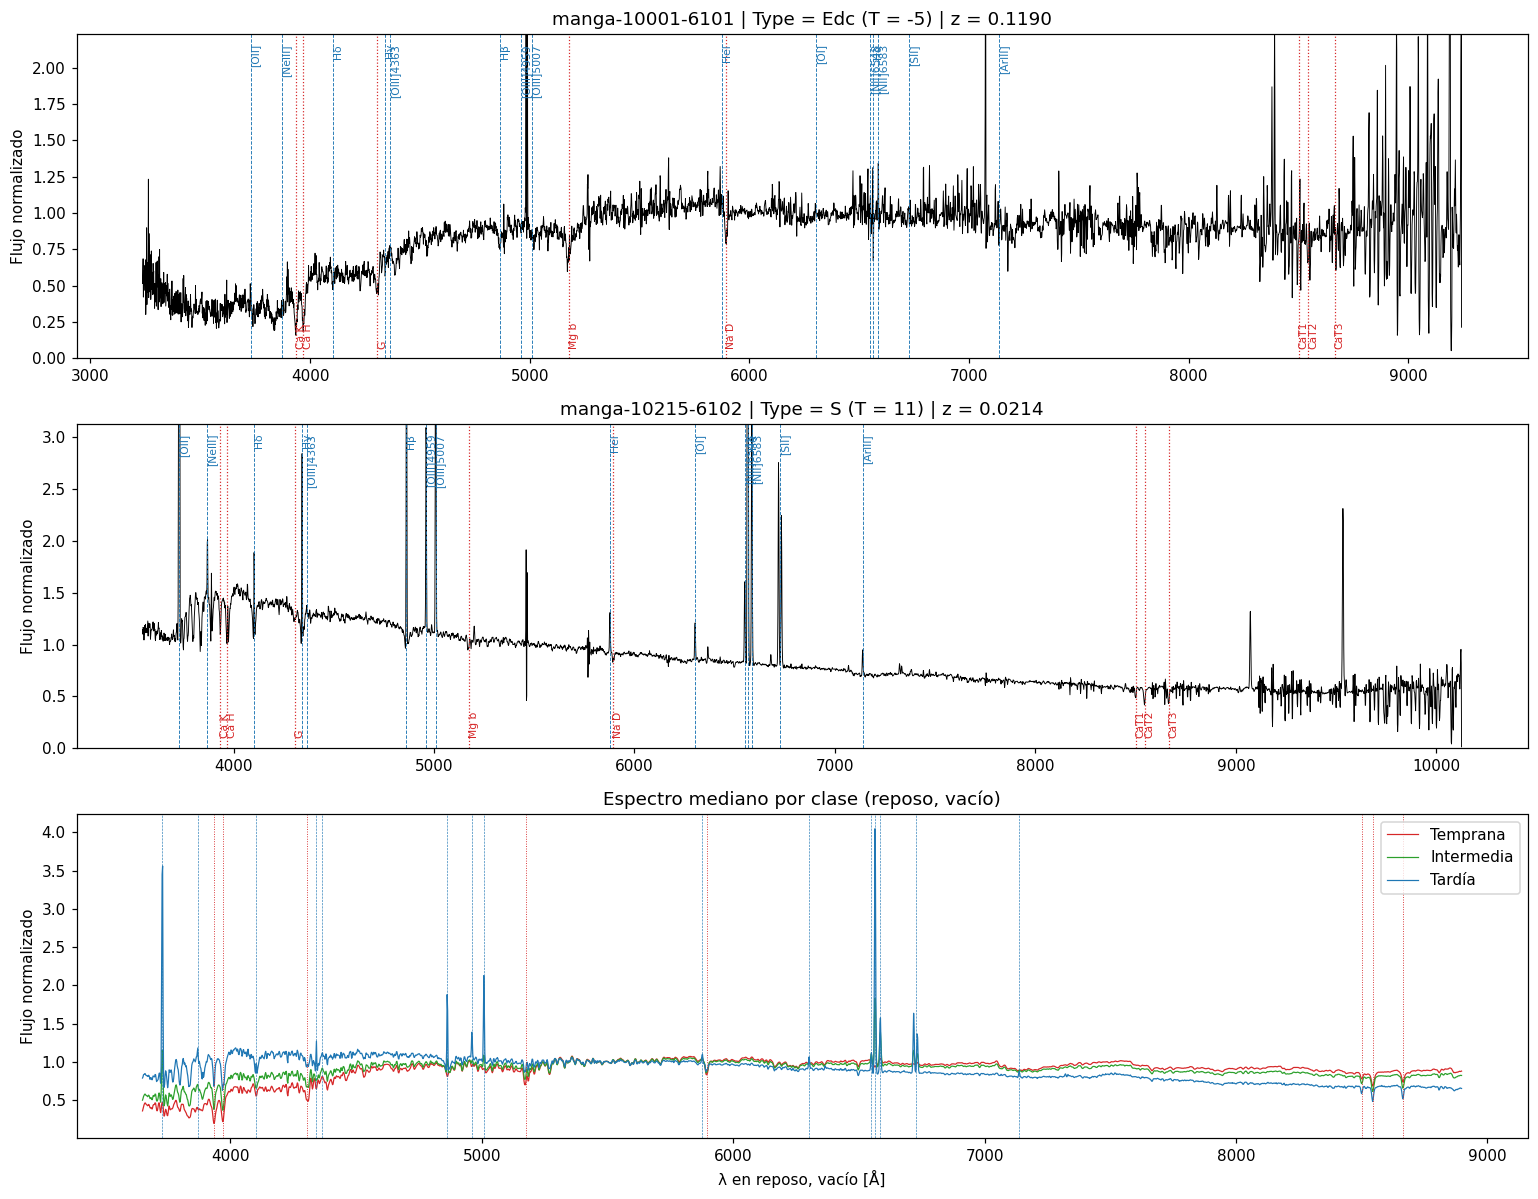

In [ ]:
# Líneas en VACÍO (Å, marco en reposo). Valores de laboratorio usados por SDSS/MaNGA.
LINEAS_EMISION = {'[OII]': 3728.5, '[NeIII]': 3869.9, 'Hδ': 4102.9, 'Hγ': 4341.7, '[OIII]4363': 4364.4,
                  'Hβ': 4862.7, '[OIII]4959': 4960.3, '[OIII]5007': 5008.2, 'HeI': 5877.3, '[OI]': 6302.0,
                  '[NII]6548': 6549.9, 'Hα': 6564.6, '[NII]6583': 6585.3, '[SII]': 6725.5, '[ArIII]': 7137.8}
LINEAS_ABSORCION = {'Ca K': 3934.8, 'Ca H': 3969.6, 'G': 4305.6, 'Mg b': 5176.7, 'Na D': 5894.6,
                    'CaT1': 8500.4, 'CaT2': 8544.4, 'CaT3': 8664.5}

def vacio_a_aire(lam_vac):
    """Ciddor (1996): λ_aire = λ_vacío / n. Solo la usamos para mostrar el tamaño del efecto."""
    s2 = (1e4 / lam_vac) ** 2
    return lam_vac / (1 + 5.792105e-2 / (238.0185 - s2) + 1.67917e-3 / (57.362 - s2))

def leer_espectro(ruta):
    """Lee un .fits.gz (astropy) o un .csv; devuelve solo WAVE y FLUX_FoV (ERROR_FoV se ignora)."""
    t = Table.from_pandas(pd.read_csv(ruta)) if '.csv' in ruta else Table.read(ruta, hdu=1)
    t.rename_columns(t.colnames, [c.upper() for c in t.colnames])   # FLUX_FoV → FLUX_FOV
    wave = np.array(t['WAVE'], dtype=float)
    flux = np.array(t['FLUX_FOV'], dtype=float)
    flux[flux == 0] = np.nan                                          # bordes sin datos
    return wave, flux

def espectro_en_reposo(ruta, z):
    """Espectro observado → reposo, normalizado por el continuo en 5450–5550 Å."""
    wave, flux = leer_espectro(ruta)
    huecos = np.where(np.diff(wave) > 2 * np.median(np.diff(wave)))[0] + 1   # solo existen en los CSV de ejemplo
    wave, flux = np.insert(wave, huecos, np.nan), np.insert(flux, huecos, np.nan)
    lam_reposo = (wave * u.AA) / (1 + z)                                  # astropy cuida las unidades
    flux_reposo = flux * (1 + z)                                         # conserva el flujo integrado
    continuo = (lam_reposo.value > 5450) & (lam_reposo.value < 5550)
    return lam_reposo, flux_reposo / np.nanmedian(flux_reposo[continuo])

print(f"Hα: vacío 6564.6 Å → aire {vacio_a_aire(6564.6):.1f} Å "
      f"(Δλ = {6564.6 - vacio_a_aire(6564.6):.2f} Å ≈ {(6564.6 - vacio_a_aire(6564.6)) / 6564.6 * 3e5:.0f} km/s)")

# Elegimos los archivos: primero los .fits.gz de Drive; si no hay, los CSV de ejemplo de GitHub
archivos = {os.path.basename(a).split('-1D')[0]: a for a in sorted(glob.glob(f'{RUTA_FITS}/*.fits*'))}
if not archivos:
    URL = 'https://raw.githubusercontent.com/Melonangie/Galaxy-Vision/main/data/sample-data/'
    archivos = {n: f'{URL}{n}-1D.csv' for n in ['manga-10001-12701', 'manga-10001-1901', 'manga-10214-12705',
                                                  'manga-10216-1902', 'manga-10217-6103']}
disponibles = [n for n in archivos if n in morf.index]
ejemplos = [min(disponibles, key=lambda n: morf.loc[n, 'Ttype']),     # la más temprana disponible
            max(disponibles, key=lambda n: morf.loc[n, 'Ttype'])]     # la más tardía disponible

fig, ejes = plt.subplots(3, 1, figsize=(14, 11))
for ax, nombre in zip(ejes[:2], ejemplos):
    z = morf.loc[nombre, 'nsa_z']
    lam, flujo = espectro_en_reposo(archivos[nombre], z)
    ax.plot(lam.value, flujo, lw=0.6, color='k')
    for etiqueta, l0 in LINEAS_EMISION.items():
        ax.axvline(l0, color='tab:blue', ls='--', lw=0.6)
        ax.text(l0, 0.97, etiqueta, color='tab:blue', rotation=90, fontsize=7, va='top', transform=ax.get_xaxis_transform())
    for etiqueta, l0 in LINEAS_ABSORCION.items():
        ax.axvline(l0, color='tab:red', ls=':', lw=0.8)
        ax.text(l0, 0.03, etiqueta, color='tab:red', rotation=90, fontsize=7, va='bottom', transform=ax.get_xaxis_transform())
    ax.set_ylim(0, np.nanpercentile(flujo, 99.5) * 1.2)
    ax.set_title(f"{nombre} | Type = {morf.loc[nombre, 'Type']} (T = {morf.loc[nombre, 'Ttype']}) | z = {z:.4f}")
    ax.set_ylabel('Flujo normalizado')

# Panel 3: espectro mediano de cada clase (los 9 885 espectros ya procesados)
for clase, color in zip(ORDEN['tres_clases'], ['tab:red', 'tab:green', 'tab:blue']):
    mediana = np.nanmedian(ESPECTROS[(df['y_tres_clases'] == clase).to_numpy()], axis=0)
    ejes[2].plot(GRID, mediana, lw=0.8, color=color, label=clase)
for l0 in LINEAS_EMISION.values():
    ejes[2].axvline(l0, color='tab:blue', ls='--', lw=0.4)
for l0 in LINEAS_ABSORCION.values():
    ejes[2].axvline(l0, color='tab:red', ls=':', lw=0.6)
ejes[2].set_title('Espectro mediano por clase (reposo, vacío)')
ejes[2].set_xlabel('λ en reposo, vacío [Å]'); ejes[2].set_ylabel('Flujo normalizado'); ejes[2].legend()
plt.tight_layout(); plt.show()

**Conclusión del espectro.** Si el redshift y la convención de vacío son correctos, las líneas caen **exactamente** sobre
los rasgos (si Hα y [NII] aparecen corridos ~2 Å, hay un error aire/vacío; si todo está corrido, un error de z).
El panel de medianas resume la física de la Celda 2:
- **Tempranas**: continuo rojo, salto en 4000 Å marcado, Ca H+K, banda G, Mg b y Na D profundos, casi sin emisión.
- **Tardías**: continuo azul, Balmer y [OII], [OIII], Hα, [NII], [SII] en emisión fuerte (formación estelar).
- **Intermedias**: un punto medio; por eso son la clase más difícil.

Estas diferencias son las que capturan las features (D4000n, EW Hα, HδA, Mg b, [NII]/Hα…) que usaremos en el modelado.

tres_clases: desbalance máx/mín = 2


,Temprana,Intermedia,Tardía
n_train,2758,3182,1473


intervalos: desbalance máx/mín = 13


,E,S0–S0a,Sa–Sab,Sb–Sbc,Sc–Sd,Sdm–Im
n_train,1330,1428,1590,1592,1352,121


detallado: desbalance máx/mín = 166


,E,S0,S0a,Sa,Sab,Sb,Sbc,Sc,Scd,Sd,Sdm,Sm,Im
n_train,1330,970,458,808,782,830,762,759,338,255,57,56,8


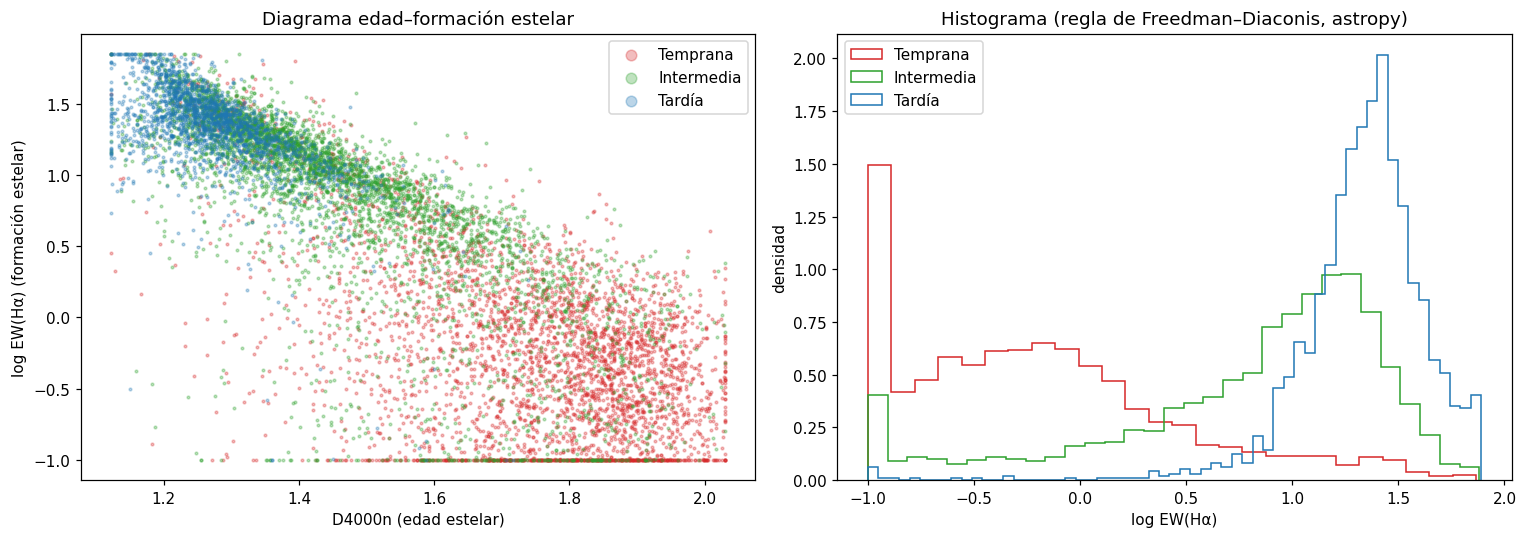

In [ ]:
# Distribución de clases en train (justifica la métrica BA) y la bimodalidad clásica D4000–EW(Hα)
for e in ESQUEMAS:
    conteo = pd.Series(Y_TR[e]).value_counts().reindex(ORDEN[e])
    print(f'{e}: desbalance máx/mín = {conteo.max() / conteo.min():.0f}')
    display(conteo.to_frame('n_train').T)

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
colores = dict(zip(ORDEN['tres_clases'], ['tab:red', 'tab:green', 'tab:blue']))
for clase, color in colores.items():
    sub = df[df['y_tres_clases'] == clase]
    ejes[0].scatter(sub['D4000n_syn'], sub['log_EW_Ha'], s=3, alpha=0.3, color=color, label=clase)
    astro_hist(sub['log_EW_Ha'].dropna(), bins='freedman', ax=ejes[1], histtype='step', density=True, color=color, label=clase)
ejes[0].set_xlabel('D4000n (edad estelar)'); ejes[0].set_ylabel('log EW(Hα) (formación estelar)'); ejes[0].legend(markerscale=4)
ejes[1].set_xlabel('log EW(Hα)'); ejes[1].set_ylabel('densidad'); ejes[1].legend()
ejes[0].set_title('Diagrama edad–formación estelar'); ejes[1].set_title('Histograma (regla de Freedman–Diaconis, astropy)')
plt.tight_layout(); plt.show()

**Conclusión del EDA.** En el esquema detallado el desbalance es extremo (E ≈ 1 330 vs Im ≈ 8 en train), así que usamos
**BA** y pesos balanceados en todos los modelos. El diagrama D4000–EW(Hα) muestra dos "nubes" (secuencia roja y nube
azul; Strateva et al. 2001; Kauffmann et al. 2003): las tempranas tienen D4000 alto y EW(Hα) bajo, las tardías lo
contrario, y las **intermedias se reparten entre ambas**. Por eso esperamos que la clase intermedia concentre los errores
y que un modelo lineal ya capture la mayor parte de la señal.

## 5. Protocolo común de entrenamiento y evaluación (CRISP-ML(Q) §3.3 "Model training")
Todos los modelos pasan por la **misma** función `evaluar_cv()`; así la comparación es justa.
- **Objetivo**: log-verosimilitud (logística, GMM) o impureza/pérdida logarítmica (árboles), con **pesos balanceados por
  clase** para no ignorar las clases raras.
- **Regularización**: C en la logística, profundidad/hojas en los árboles. Se elige con `GridSearchCV` (3 pliegues)
  **solo dentro de train**.
- **Validación cruzada repetida**: 5 pliegues estratificados × 3 semillas = 15 medidas por modelo. Esto da la media **y**
  la varianza (reproducibilidad del resultado). Con las mismas semillas, todos los modelos ven los mismos pliegues, lo que
  permite comparaciones emparejadas.
- **Prueba estadística**: t corregida de Nadeau & Bengio (2003). La t normal subestima la varianza porque los pliegues
  comparten datos de entrenamiento; la corrección multiplica la varianza por (1/n + n_test/n_train).
- **Bitácora**: cada pliegue queda registrado en `REGISTRO` (documentación experimental, CRISP-ML(Q) §3.3.1).
- El **test** (2 472 galaxias) no se toca hasta la Celda 42.

In [ ]:
REGISTRO = []      # bitácora: una fila por (modelo, esquema, semilla, pliegue)
MODELOS  = {}      # (nombre, esquema) -> (estimador sin entrenar, columnas que usa)

def metricas(y_real, y_pred, e, t_real):
    """Mismas métricas que el baseline: nominales (BA, F1) y ordinales (κ cuadrático, ±1 clase, MAE en T)."""
    pos = {c: i for i, c in enumerate(ORDEN[e])}                 # posición de cada clase en la secuencia E → Im
    i_real = np.array([pos[c] for c in y_real])
    i_pred = np.array([pos[c] for c in y_pred])
    t_pred = np.array([T_REP[e][c] for c in y_pred])             # T típico de la clase predicha
    K = len(ORDEN[e])
    ba = balanced_accuracy_score(y_real, y_pred)
    return {'BA': ba,
            'mejora_azar': (ba - 1 / K) / (1 - 1 / K),             # 0 = azar, 1 = perfecto
            'F1_macro': f1_score(y_real, y_pred, average='macro'),
            'kappa_cuad': cohen_kappa_score(i_real, i_pred, weights='quadratic'),
            'acierto_±1': np.mean(np.abs(i_real - i_pred) <= 1),
            'MAE_T': np.mean(np.abs(t_real - t_pred))}

def matriz(cols, mascara):
    """Matriz X (numpy) para las filas de `mascara`: features tabulares o el espectro completo."""
    if isinstance(cols, str) and cols == 'espectro':
        return ESPECTROS[mascara]
    return df.loc[mascara, cols].to_numpy(dtype=float)

def ba_cv(nombre, e):
    """BA de los 15 pliegues de un modelo, en orden (semilla, pliegue) para poder emparejar."""
    r = pd.DataFrame(REGISTRO)
    r = r[(r['modelo'] == nombre) & (r['esquema'] == e)].sort_values(['semilla', 'pliegue'])
    return r['BA'].to_numpy()

def evaluar_cv(nombre, modelo, cols, e, semillas=None):
    """CV estratificada repetida. Guarda las métricas de cada pliegue en REGISTRO."""
    REGISTRO[:] = [r for r in REGISTRO if not (r['modelo'] == nombre and r['esquema'] == e)]  # por si se re-ejecuta
    X, y, t = matriz(cols, TRAIN), Y_TR[e], T_TR
    for s in (semillas or SEMILLAS):
        pliegues = StratifiedKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=s)
        for k, (i_tr, i_va) in enumerate(pliegues.split(X, y)):
            m = clone(modelo)                                     # modelo nuevo, sin datos previos
            t0 = time.time()
            m.fit(X[i_tr], y[i_tr])
            t_fit = time.time() - t0
            pred = m.predict(X[i_va])
            REGISTRO.append({'modelo': nombre, 'esquema': e, 'semilla': s, 'pliegue': k,
                             't_fit_s': t_fit, **metricas(y[i_va], pred, e, t[i_va])})
    MODELOS[(nombre, e)] = (modelo, cols)
    ba = ba_cv(nombre, e)
    print(f'{e:12s} | {nombre:38s} | BA = {ba.mean():.3f} ± {ba.std():.3f}')

def t_corregido(a, b, e):
    """Prueba t corregida (Nadeau & Bengio 2003) para ΔBA = a − b sobre los mismos pliegues."""
    d = ba_cv(a, e) - ba_cv(b, e)
    if len(d) < 2 or np.allclose(d, 0):
        return d.mean() if len(d) else 0.0, 1.0
    correccion = 1 / len(d) + 1 / (N_PLIEGUES - 1)           # n_test / n_train = 1 / (k − 1)
    t = d.mean() / np.sqrt(correccion * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), df=len(d) - 1)

def afinar(nombre, modelo, rejilla, cols, e):
    """Búsqueda de hiperparámetros con 3 pliegues SOLO en train, optimizando BA."""
    if MODO_RAPIDO:
        return modelo
    busqueda = GridSearchCV(modelo, rejilla, scoring='balanced_accuracy', n_jobs=-1,
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEMILLA))
    busqueda.fit(matriz(cols, TRAIN), Y_TR[e])
    MEJORES_HIPER[(nombre, e)] = busqueda.best_params_
    print(f'   {nombre} [{e}] mejores hiperparámetros: {busqueda.best_params_}')
    return clone(busqueda.best_estimator_)                    # con los mejores hiperparámetros, sin entrenar

MEJORES_HIPER = {}

## 6. Los modelos candidatos, de menor a mayor capacidad
CRISP-ML(Q): *"empezar con modelos de baja capacidad, que sirven de baseline, y aumentar la capacidad gradualmente,
validando cada paso"*. No hay un modelo mejor para todos los problemas (teorema *no free lunch*, Wolpert 1996).

| Paso | Modelo | Capacidad | Por qué lo probamos |
|---|---|---|---|
| M0 | Azar (clase más frecuente) | nula | Piso: BA = 1/K |
| M1 | **Baseline**: logística top-10 | lineal | Reproducir el punto de partida |
| M2 | GMM-Bayes (astroML) | cuadrática | Clasificador generativo: modela cada clase con gaussianas (Ivezić et al. 2014, *Statistics, Data Mining and ML in Astronomy*) |
| M3 | Logística afinada | lineal | Más features + regularización elegida por CV |
| M4 | Random Forest (Breiman 2001, Mach. Learn. 45, 5) | no lineal | Interacciones (p. ej. b/a × color) y robustez |
| M5 | HistGradientBoosting (Friedman 2001, Ann. Stat. 29, 1189) | no lineal | Suele ser el mejor en tablas (Grinsztajn et al. 2022); acepta NaN |
| M6 | Ordinal de Frank & Hall | lineal + orden | Conocimiento del dominio: E < S0 < … < Im |
| M7 | PCA del espectro + logística | lineal sobre representación aprendida | Representación no supervisada del espectro completo (Yip et al. 2004) |
| M8 | Ensamble de los 3 mejores | combinación | Reduce varianza (Dietterich 2000, MCS, LNCS 1857, 1) |
| C1, C2 | Versiones comprimidas | menor | Compresión del modelo (CRISP-ML(Q)) |

In [ ]:
def logistica(C=1.0):
    """Imputar mediana → estandarizar → logística multinomial con pesos balanceados (igual que el baseline)."""
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                         LogisticRegression(C=C, class_weight='balanced', max_iter=3000))

def gmm_bayes():
    """astroML: una gaussiana completa por clase + regla de Bayes (las clases raras pesan por su prior)."""
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), GMMBayes(n_components=np.array([1])))

def bosque(**kw):
    """Random Forest; 'balanced_subsample' re-pesa las clases en cada árbol."""
    return make_pipeline(SimpleImputer(strategy='median'),
                         RandomForestClassifier(n_estimators=300, class_weight='balanced_subsample',
                                                n_jobs=-1, random_state=SEMILLA, **kw))

def boosting(**kw):
    """Gradient boosting por histogramas; maneja los NaN sin imputar."""
    return HistGradientBoostingClassifier(class_weight='balanced', random_state=SEMILLA, **kw)

def pca_espectro(n=30, C=1.0):
    """Representación no supervisada: n componentes principales del espectro → logística."""
    return make_pipeline(SimpleImputer(strategy='median'), PCA(n_components=n, random_state=SEMILLA),
                         StandardScaler(), LogisticRegression(C=C, class_weight='balanced', max_iter=3000))

def proba_en_orden(modelo, X, orden):
    """predict_proba con las columnas en el orden físico de las clases (sklearn las ordena alfabéticamente)."""
    P = modelo.predict_proba(X)
    clases = list(modelo.classes_)
    return P[:, [clases.index(c) for c in orden]]


class OrdinalFrankHall(ClassifierMixin, BaseEstimator):
    """Clasificación ordinal (Frank & Hall 2001).
    Con K clases ordenadas entrena K−1 logísticas binarias "¿la clase está después de k?" y obtiene
    P(clase = k) = P(> k−1) − P(> k). Así el modelo 'sabe' que E está más cerca de S0 que de Sc."""
    def __init__(self, orden=None, C=1.0):
        self.orden = orden
        self.C = C

    def fit(self, X, y):
        self.classes_ = np.array(self.orden)
        pos = {c: i for i, c in enumerate(self.orden)}
        rango = np.array([pos[c] for c in y])
        self.modelos_ = [logistica(self.C).fit(X, (rango > k).astype(int)) for k in range(len(self.orden) - 1)]
        return self

    def predict_proba(self, X):
        mayor = np.column_stack([m.predict_proba(X)[:, 1] for m in self.modelos_])   # P(clase > k)
        mayor = np.minimum.accumulate(mayor, axis=1)                                 # debe decrecer con k
        n = len(mayor)
        acumulada = np.column_stack([np.ones(n), mayor, np.zeros(n)])
        return acumulada[:, :-1] - acumulada[:, 1:]                                 # P(clase = k)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


class EnsamblePromedio(ClassifierMixin, BaseEstimator):
    """Promedia las probabilidades de varios modelos (votación suave)."""
    def __init__(self, modelos=None, orden=None):
        self.modelos = modelos
        self.orden = orden

    def fit(self, X, y):
        self.classes_ = np.array(self.orden)
        self.modelos_ = [clone(m).fit(X, y) for m in self.modelos]
        return self

    def predict_proba(self, X):
        return np.mean([proba_en_orden(m, X, self.orden) for m in self.modelos_], axis=0)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

## 7. Paso 1 — M0 y M1: reproducir el baseline (control de reproducibilidad)
Antes de mejorar algo hay que **reproducir** el punto de partida. Hacemos dos controles:
1. **Reproducibilidad del método**: cargamos los modelos guardados del baseline (`baseline_*.joblib`) y comprobamos que
   predicen lo mismo que `predicciones_test.ecsv`. (Solo **leemos** sus predicciones; no usamos el test para decidir.)
2. **Reproducibilidad del resultado**: la BA de CV de M1 debe coincidir con la del baseline (≈ 0.760 / 0.566 / 0.291) dentro
   de ~0.01. Si no, cambió algo en los datos o en el código y la comparación no sería válida.

In [ ]:
BASELINE = 'M1 Baseline logística top-10'

for e in ESQUEMAS:
    # Control 1: el modelo guardado del baseline reproduce sus propias predicciones
    guardado = load(f'{RUTA_BASE}/baseline_{e}.joblib')            # dict {'modelo', 'columnas'}
    nombres_test = df.index[TEST]
    pred = guardado['modelo'].predict(df.loc[TEST, guardado['columnas']])
    coincide = np.mean(pred == PRED_BASE.loc[nombres_test, f'pred_{e}'].to_numpy())
    print(f'{e}: columnas iguales a TOP10 = {guardado["columnas"] == TOP10[e]} | predicciones idénticas = {coincide:.1%}')

    # Control 2: misma BA en CV
    evaluar_cv('M0 Azar (clase más frecuente)', DummyClassifier(strategy='most_frequent'), TOP10[e], e)
    evaluar_cv(BASELINE, logistica(), TOP10[e], e)
    ref = CV_BASE.query("modelo == '2 Logística (top-10)' and esquema == @e")['balanced_acc'].iloc[0]
    print(f'{"":12s}   → BA de CV reportada por el baseline: {ref:.3f}\n')

tres_clases: columnas iguales a TOP10 = True | predicciones idénticas = 100.0%
tres_clases  | M0 Azar (clase más frecuente)          | BA = 0.333 ± 0.000
tres_clases  | M1 Baseline logística top-10           | BA = 0.760 ± 0.008
               → BA de CV reportada por el baseline: 0.760

intervalos: columnas iguales a TOP10 = True | predicciones idénticas = 100.0%
intervalos   | M0 Azar (clase más frecuente)          | BA = 0.167 ± 0.000
intervalos   | M1 Baseline logística top-10           | BA = 0.566 ± 0.015
               → BA de CV reportada por el baseline: 0.566

detallado: columnas iguales a TOP10 = True | predicciones idénticas = 100.0%
detallado    | M0 Azar (clase más frecuente)          | BA = 0.077 ± 0.000
detallado    | M1 Baseline logística top-10           | BA = 0.292 ± 0.018
               → BA de CV reportada por el baseline: 0.291



**Conclusión del Paso 1.** Si las predicciones del modelo guardado coinciden al 100 % y la BA de M1 está a ±0.01 de la
del baseline (la pequeña diferencia viene de usar 3 semillas en lugar de 1), el protocolo es fiel y la comparación con
modelos nuevos es válida. M0 fija el piso (BA = 1/K: 0.333, 0.167 y 0.077). El baseline ya está muy por encima del azar
(mejora sobre azar ≈ 0.64 en tres clases) y cerca del techo por ruido de etiqueta (0.829 en tres clases), así que
**el margen real de mejora es pequeño**, sobre todo en `tres_clases`.

## 8. Paso 2 — ¿Qué conjunto de features? (selección de datos para el modelado)
CRISP-ML(Q) advierte que más features exigen más datos (maldición de la dimensionalidad) y abren puertas a errores.
Comparamos **top-10**, **32 representativas** y **las 51** con dos familias muy distintas: lineal (logística) y árboles
(HistGradientBoosting). Elegimos el **conjunto más pequeño** que no sea significativamente peor (p ≥ 0.05) que el mejor,
en **ambas** familias (parsimonia).

In [ ]:
CONJUNTOS = {'top10': lambda e: TOP10[e], 'reps32': lambda e: REPS, 'todas51': lambda e: FEATURES}
COLS_SEL = {}

for e in ESQUEMAS:
    for c, columnas in CONJUNTOS.items():
        evaluar_cv(f'FS {c} | LR', logistica(), columnas(e), e)
        evaluar_cv(f'FS {c} | HGB', boosting(), columnas(e), e)

    # Recorremos del conjunto más pequeño al más grande y nos quedamos con el primero que "empata" con el mejor
    for c in CONJUNTOS:
        empatado = True
        for alg in ['LR', 'HGB']:
            mejor = max([f'FS {k} | {alg}' for k in CONJUNTOS], key=lambda n: ba_cv(n, e).mean())
            dif, p = t_corregido(f'FS {c} | {alg}', mejor, e)
            print(f'   {e} | {c:8s} {alg:4s} vs mejor ({mejor}): ΔBA = {dif:+.3f}, p = {p:.3f}')
            if dif < 0 and p < 0.05:
                empatado = False
        if empatado:
            COLS_SEL[e] = CONJUNTOS[c](e)
            print(f'→ {e}: usamos {c} ({len(COLS_SEL[e])} features)\n')
            break

tres_clases  | FS top10 | LR                          | BA = 0.760 ± 0.008
tres_clases  | FS top10 | HGB                         | BA = 0.767 ± 0.010
tres_clases  | FS reps32 | LR                         | BA = 0.768 ± 0.009
tres_clases  | FS reps32 | HGB                        | BA = 0.785 ± 0.009
tres_clases  | FS todas51 | LR                        | BA = 0.772 ± 0.010
tres_clases  | FS todas51 | HGB                       | BA = 0.783 ± 0.008
   tres_clases | top10    LR   vs mejor (FS todas51 | LR): ΔBA = -0.012, p = 0.009
   tres_clases | top10    HGB  vs mejor (FS reps32 | HGB): ΔBA = -0.018, p = 0.017
   tres_clases | reps32   LR   vs mejor (FS todas51 | LR): ΔBA = -0.005, p = 0.229
   tres_clases | reps32   HGB  vs mejor (FS reps32 | HGB): ΔBA = +0.000, p = 1.000
→ tres_clases: usamos reps32 (32 features)

intervalos   | FS top10 | LR                          | BA = 0.566 ± 0.015
intervalos   | FS top10 | HGB                         | BA = 0.517 ± 0.018
intervalos   | FS reps32

**Conclusión del Paso 2.** Según la ablación del baseline, la logística rinde casi igual con top-10 que con 51 features
(0.759 vs 0.771 en tres clases): la información está concentrada en pocas variables físicas (EW Hα, D4000, HδA,
[NII]/Hα, PC1, Σ₉₀, b/a). Los **árboles** sí pueden ganar algo con más features porque explotan interacciones.
Si un conjunto mayor gana con p < 0.05, lo usamos en M3–M8; si no, nos quedamos con el más simple. Revisa en la salida
qué conjunto quedó en cada esquema.

## 9. Paso 3 — Aumentar la capacidad: M2 → M5
Afinamos los hiperparámetros dentro de train y evaluamos con la misma CV repetida. GMM-Bayes usa top-10 (como el
baseline) porque una gaussiana completa en 51 dimensiones con 8 galaxias Im sería degenerada.
Nota: afinar y evaluar en el mismo train da una estimación ligeramente optimista; el test ciego (Celda 42) lo corrige.

In [ ]:
for e in ESQUEMAS:
    cols = COLS_SEL[e]
    evaluar_cv('M2 GMM-Bayes top-10 (astroML)', gmm_bayes(), TOP10[e], e)

    m3 = afinar('M3', logistica(), {'logisticregression__C': [0.01, 0.1, 1, 10]}, cols, e)
    evaluar_cv('M3 Logística afinada', m3, cols, e)

    m4 = afinar('M4', bosque(), {'randomforestclassifier__min_samples_leaf': [1, 5, 20],
                                 'randomforestclassifier__max_features': ['sqrt', 0.3]}, cols, e)
    evaluar_cv('M4 Random Forest', m4, cols, e)

    m5 = afinar('M5', boosting(), {'learning_rate': [0.05, 0.1], 'max_leaf_nodes': [15, 31],
                                   'l2_regularization': [0.0, 1.0]}, cols, e)
    evaluar_cv('M5 HistGradientBoosting', m5, cols, e)
    print()

tres_clases  | M2 GMM-Bayes top-10 (astroML)          | BA = 0.742 ± 0.008
   M3 [tres_clases] mejores hiperparámetros: {'logisticregression__C': 0.1}
tres_clases  | M3 Logística afinada                   | BA = 0.768 ± 0.010
   M4 [tres_clases] mejores hiperparámetros: {'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__min_samples_leaf': 20}
tres_clases  | M4 Random Forest                       | BA = 0.786 ± 0.010
   M5 [tres_clases] mejores hiperparámetros: {'l2_regularization': 0.0, 'learning_rate': 0.05, 'max_leaf_nodes': 15}
tres_clases  | M5 HistGradientBoosting                | BA = 0.796 ± 0.009

intervalos   | M2 GMM-Bayes top-10 (astroML)          | BA = 0.489 ± 0.011
   M3 [intervalos] mejores hiperparámetros: {'logisticregression__C': 10}
intervalos   | M3 Logística afinada                   | BA = 0.583 ± 0.013
   M4 [intervalos] mejores hiperparámetros: {'randomforestclassifier__max_features': 0.3, 'randomforestclassifier__min_samples_leaf': 20}
inter

**Conclusión del Paso 3.** Lo que esperamos, según el baseline (confírmalo con tu salida):
- **M2 (GMM-Bayes)** queda por debajo de la logística (en el baseline: 0.734 vs 0.760 en tres clases). Supone que cada
  clase es gaussiana, pero índices como EW(Hα) son bimodales dentro de una misma clase (espirales con y sin formación).
- **M3 ≈ M1**: con ~7 400 galaxias y ≤ 51 features no hay sobreajuste lineal, así que la regularización cambia poco.
- **M4 y M5 (árboles)** ganan de +0.01 a +0.03 de BA, sobre todo en `detallado` e `intervalos`, y tienen mejor κ y MAE_T
  (en el baseline, RF: κ ≈ 0.84 vs 0.79 de la logística).
Cada paso de capacidad solo se justifica si mejora con p < 0.05; si no, CRISP-ML(Q) recomienda quedarse con el más simple.

## 10. Paso 4 — Incorporar conocimiento del dominio, validado de forma aislada
CRISP-ML(Q): *"validar el conocimiento del dominio incorporado de forma aislada contra un baseline; si no mejora la calidad,
debe eliminarse para evitar sesgos falsos"*. Probamos dos ideas físicas, cada una contra su versión sin ella:
1. **Orden de las clases (M6 vs M3).** La secuencia de Hubble es ordinal; la logística multinomial lo ignora. El modelo de
   Frank & Hall lo usa. Esperamos un κ cuadrático mayor y un MAE_T menor (menos errores "lejanos").
2. **Clase WHAN (M1 + WHAN vs M1).** El diagrama WHAN (Cid Fernandes et al. 2011) separa galaxias con formación estelar,
   AGN y galaxias "retiradas" (ionizadas por estrellas viejas, típicas de E/S0). Son cortes no lineales en EW(Hα) y
   [NII]/Hα que la logística no puede trazar por sí sola.

In [ ]:
for e in ESQUEMAS:
    cols = COLS_SEL[e]
    m6 = afinar('M6', OrdinalFrankHall(orden=ORDEN[e]), {'C': [0.01, 0.1, 1, 10]}, cols, e)
    evaluar_cv('M6 Ordinal Frank-Hall', m6, cols, e)
    evaluar_cv('DK Baseline + WHAN', logistica(), TOP10[e] + COLS_WHAN, e)

    # Comparación aislada: misma familia, con y sin el conocimiento del dominio
    r = pd.DataFrame(REGISTRO).query('esquema == @e').groupby('modelo')[['BA', 'kappa_cuad', 'MAE_T']].mean()
    for nuevo, base in [('M6 Ordinal Frank-Hall', 'M3 Logística afinada'), ('DK Baseline + WHAN', BASELINE)]:
        dif, p = t_corregido(nuevo, base, e)
        print(f'   {nuevo} vs {base}: ΔBA = {dif:+.3f} (p = {p:.3f}) | '
              f'Δκ = {r.loc[nuevo, "kappa_cuad"] - r.loc[base, "kappa_cuad"]:+.3f} | '
              f'ΔMAE_T = {r.loc[nuevo, "MAE_T"] - r.loc[base, "MAE_T"]:+.3f}')
    print()

**Conclusión del Paso 4.**
- **Ordinal.** Lo esperado es una BA parecida a M3, pero **κ más alto y MAE_T más bajo**: cuando falla, el modelo ordinal
  confunde clases vecinas (Sa↔Sab) en lugar de lejanas (E↔Sc). Ese tipo de error es compatible con el desacuerdo
  entre clasificadores humanos (Naim et al. 1995). Si Δκ > 0, el conocimiento ordinal **se conserva**.
- **WHAN.** Si ΔBA ≈ 0 (p > 0.05), la información de WHAN ya está en EW(Hα) y [NII]/Hα, que están en el top-10, y la
  **descartamos** para no añadir complejidad sin beneficio. Si mejora con p < 0.05, se justifica añadirla.

## 11. Paso 5 — Datos sin etiqueta / representación aprendida: PCA del espectro completo
CRISP-ML(Q) sugiere aprovechar representaciones aprendidas sin etiquetas. El PCA es un aprendizaje **no supervisado**
del espectro: los primeros eigenespectros siguen la secuencia de Hubble (Connolly et al. 1995; Yip et al. 2004).
M7 usa **solo el espectro** en reposo (2 625 píxeles) → PCA → logística, sin ninguna feature hecha a mano. El PCA se
ajusta dentro de cada pliegue (sin fuga de información). Elegimos el número de componentes por CV.

In [ ]:
for e in ESQUEMAS:
    m7 = afinar('M7', pca_espectro(), {'pca__n_components': [10, 30, 60]}, 'espectro', e)
    evaluar_cv('M7 PCA del espectro + logística', m7, 'espectro', e)
    dif, p = t_corregido('M7 PCA del espectro + logística', BASELINE, e)
    print(f'   M7 vs baseline: ΔBA = {dif:+.3f} (p = {p:.3f})\n')

# Visualizamos los 3 primeros eigenespectros (ajustados con todo el train de tres clases)
pca_vis = make_pipeline(SimpleImputer(strategy='median'), PCA(n_components=3, random_state=SEMILLA))
pca_vis.fit(ESPECTROS[TRAIN])
pixeles_validos = ~np.all(np.isnan(ESPECTROS[TRAIN]), axis=0)     # el imputador descarta columnas sin datos
fig, ax = plt.subplots(figsize=(14, 4))
for i, comp in enumerate(pca_vis.named_steps['pca'].components_):
    ax.plot(GRID[pixeles_validos], comp + 0.06 * i, lw=0.7, label=f'PC{i + 1}')
for l0 in list(LINEAS_EMISION.values()) + list(LINEAS_ABSORCION.values()):
    ax.axvline(l0, color='gray', lw=0.3)
ax.set_xlabel('λ en reposo, vacío [Å]'); ax.set_title('Eigenespectros (desplazados en vertical)'); ax.legend()
plt.show()

**Conclusión del Paso 5.** En la ablación del baseline, el "espectro completo" con 46 features dio BA ≈ 0.73 en tres
clases. Esperamos que M7 quede **cerca pero por debajo** del baseline. El espectro contiene la información de poblaciones
estelares y gas (PC1 ≈ continuo rojo vs azul + líneas de emisión; picos en Hα, [OII], Ca H+K), pero **no** la información
estructural (b/a, Σ₉₀, tamaño) que sí aportan las features de catálogo. Si M7 empata con M1, demuestra que una
representación sin ingeniería manual ya captura casi toda la señal espectral.

## 12. Paso 6 — Compresión del modelo
CRISP-ML(Q) propone obtener modelos más compactos. Probamos dos versiones "comprimidas":
- **C1**: logística con solo las **5** primeras features del consenso.
- **C2**: HistGradientBoosting pequeño (7 hojas, 50 iteraciones) con las features seleccionadas.
Si pierden poco rendimiento, pueden ganar la selección final por parsimonia.

In [ ]:
for e in ESQUEMAS:
    evaluar_cv('C1 Logística top-5 (comprimida)', logistica(), TOP10[e][:5], e)
    evaluar_cv('C2 HGB pequeño (comprimido)', boosting(max_leaf_nodes=7, max_iter=50), COLS_SEL[e], e)
    print(f'   features de C1: {TOP10[e][:5]}\n')

**Conclusión del Paso 6.** Si C1 pierde menos de ~0.01–0.02 de BA frente al baseline, **cinco variables físicas** (EW Hα,
D4000/HδA, [NII]/Hα, PC1…) contienen casi toda la información morfológica del espectro. Es un resultado científico en sí:
la morfología espectral es, en esencia, **edad estelar + formación estelar + ionización**. C2 muestra cuánta capacidad
de árbol se necesita realmente.

## 13. Paso 7 — Ensamble de los 3 mejores modelos probabilísticos
Un ensamble promedia las probabilidades de varios modelos. Si sus errores no están correlacionados, la varianza baja
(Dietterich 2000). Elegimos los 3 mejores en BA entre M3–M6, que usan las mismas features. La dispersión entre los
miembros también sirve como medida de incertidumbre (Lakshminarayanan et al. 2017, NeurIPS).

In [ ]:
CANDIDATOS_ENSAMBLE = ['M3 Logística afinada', 'M4 Random Forest', 'M5 HistGradientBoosting', 'M6 Ordinal Frank-Hall']
MIEMBROS = {}
for e in ESQUEMAS:
    MIEMBROS[e] = sorted(CANDIDATOS_ENSAMBLE, key=lambda n: ba_cv(n, e).mean(), reverse=True)[:3]
    print(f'{e} → miembros: {MIEMBROS[e]}')
    ensamble = EnsamblePromedio(modelos=[MODELOS[(n, e)][0] for n in MIEMBROS[e]], orden=ORDEN[e])
    evaluar_cv('M8 Ensamble top-3', ensamble, COLS_SEL[e], e)

**Conclusión del Paso 7.** El ensamble suele igualar o superar ligeramente (+0.005 a +0.02) a su mejor miembro, a
cambio de más tamaño, más tiempo y menos explicabilidad. Si no mejora con p < 0.05, la regla de selección (Celda 40)
preferirá un modelo individual.

## 14. Reproducibilidad del resultado: resumen de la CV
CRISP-ML(Q) §3.3.1: *"validar el rendimiento medio y evaluar la varianza del modelo con distintas semillas; reportar
solo la mejor corrida es una práctica dudosa"*.
- `BA_std_semillas`: cuánto cambia la BA media al cambiar **solo** la semilla de partición.
- `ΔBA_vs_M1` y `p_vs_M1`: comparación con el baseline mediante la t corregida.

In [ ]:
R = pd.DataFrame(REGISTRO)
R = R[~R['modelo'].str.startswith('FS')]                 # quitamos los experimentos de selección de features

RESUMEN = R.groupby(['esquema', 'modelo'])[['BA', 'F1_macro', 'kappa_cuad', 'acierto_±1', 'MAE_T', 't_fit_s']].mean()
RESUMEN['BA_std_pliegues'] = R.groupby(['esquema', 'modelo'])['BA'].std()
RESUMEN['BA_std_semillas'] = R.groupby(['esquema', 'modelo', 'semilla'])['BA'].mean().groupby(['esquema', 'modelo']).std()
for (e, n) in RESUMEN.index:
    dif, p = t_corregido(n, BASELINE, e)
    RESUMEN.loc[(e, n), 'ΔBA_vs_M1'] = dif
    RESUMEN.loc[(e, n), 'p_vs_M1'] = p

for e in ESQUEMAS:
    print(f'\n=== {e} | techo por ruido de etiqueta = {FICHA.loc[e, "techo_σ1.3"]:.3f} ===')
    display(RESUMEN.loc[e].sort_values('BA', ascending=False).round(3))

# Gráfica: BA media ± desviación de los 15 pliegues
fig, ejes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for ax, e in zip(ejes, ESQUEMAS):
    t = RESUMEN.loc[e].sort_values('BA')
    ax.errorbar(t['BA'], range(len(t)), xerr=t['BA_std_pliegues'], fmt='o', capsize=3)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index, fontsize=8)
    ax.axvline(FICHA.loc[e, 'techo_σ1.3'], color='r', ls='--', label='techo σ_T = 1.3')
    ax.axvline(1 / len(ORDEN[e]), color='gray', ls=':', label='azar')
    ax.set_xlabel('BA (CV 5×3)'); ax.set_title(e); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusión de la CV.** Lee la tabla con tres preguntas:
1. **¿Algún modelo supera a M1 con p < 0.05?** Si ninguno lo hace, el baseline ya extrae casi toda la información.
2. **¿`BA_std_semillas` (típicamente 0.003–0.01) es menor que ΔBA?** Si no, la "mejora" es ruido de partición.
3. **¿Mejoran κ y MAE_T aunque BA no mejore?** En morfología importa **cuán lejos** está el error.

Todos los modelos deben quedar por debajo del techo (0.829 / 0.695 / 0.405). Eso confirma que el límite lo pone el
**ruido de las etiquetas visuales** y la falta de información estructural en el espectro, no la capacidad del modelo.

## 15. Medidas de calidad de CRISP-ML(Q) (Tabla 2) más allá del rendimiento
Las medimos en una partición interna **80/20 dentro de train** (el test sigue intacto):
- **Robustez**: BA con ruido gaussiano de 0.25σ en cada feature y con 10 % de valores borrados, dividida entre la BA limpia.
  Simula errores de medición y features que no se pudieron medir (p. ej. líneas no detectadas).
- **Escalabilidad**: segundos de entrenamiento.
- **Demanda de recursos**: milisegundos de predicción por galaxia.
- **Complejidad**: tamaño del modelo serializado (KB).
- **Explicabilidad**: escala fija por familia, definida en la Celda 4.

In [ ]:
EXPLICABILIDAD = {'M0': 1.0, 'M1': 1.0, 'M2': 0.8, 'M3': 1.0, 'M4': 0.5, 'M5': 0.5, 'M6': 1.0,
                  'M7': 0.6, 'M8': 0.3, 'C1': 1.0, 'C2': 0.6, 'DK': 1.0}

def perturbar(X, tipo):
    """'ruido': suma N(0, 0.25σ) a cada columna; 'faltantes': borra al azar el 10 % de los valores."""
    rng = np.random.default_rng(SEMILLA)
    X = np.array(X, dtype=float)
    if tipo == 'ruido':
        return X + rng.normal(0, 0.25, X.shape) * np.nanstd(X, axis=0)
    X[rng.random(X.shape) < 0.10] = np.nan
    return X

# Partición interna 80/20 de train, estratificada por T-type
idx_train = np.where(TRAIN)[0]
i_sub, i_val = train_test_split(idx_train, test_size=0.2, stratify=df['Ttype'].to_numpy()[idx_train], random_state=SEMILLA)
SUB, VAL = np.zeros(len(df), bool), np.zeros(len(df), bool)
SUB[i_sub], VAL[i_val] = True, True

filas = []
for (e, n) in RESUMEN.index:
    modelo, cols = MODELOS[(n, e)]
    y_sub, y_val = df.loc[SUB, f'y_{e}'].to_numpy(), df.loc[VAL, f'y_{e}'].to_numpy()
    X_val = matriz(cols, VAL)

    m = clone(modelo)
    t0 = time.time(); m.fit(matriz(cols, SUB), y_sub); t_fit = time.time() - t0
    t0 = time.time(); pred = m.predict(X_val); ms = 1000 * (time.time() - t0) / len(X_val)

    ba_limpia = balanced_accuracy_score(y_val, pred)
    ba_ruido = balanced_accuracy_score(y_val, m.predict(perturbar(X_val, 'ruido')))
    ba_falt = balanced_accuracy_score(y_val, m.predict(perturbar(X_val, 'faltantes')))
    filas.append({'esquema': e, 'modelo': n,
                  'rob_ruido': ba_ruido / ba_limpia, 'rob_faltantes': ba_falt / ba_limpia,
                  'robustez': min(1.0, (ba_ruido + ba_falt) / (2 * ba_limpia)),
                  'explicabilidad': EXPLICABILIDAD[n.split()[0]],
                  'tamano_kb': len(pickle.dumps(m)) / 1024,
                  'ms_por_galaxia': ms, 't_fit_s': t_fit})

CALIDAD = pd.DataFrame(filas).set_index(['esquema', 'modelo'])
for e in ESQUEMAS:
    print(f'\n=== {e} ===')
    display(CALIDAD.loc[e].join(RESUMEN.loc[e, ['BA']]).sort_values('BA', ascending=False).round(4))

**Conclusión de calidad.** Lo esperado:
- **Lineales y ordinales**: conservan > 95 % de su BA con ruido, pesan pocos KB, predicen en microsegundos y son
  completamente interpretables (cada coeficiente dice cuánto empuja una feature hacia "más tardía").
- **Árboles**: también robustos (HGB maneja los NaN de forma nativa), pero pesan de cientos de KB a decenas de MB.
- **PCA del espectro**: sensible a los faltantes, porque cada píxel borrado cambia la proyección.
- **Ensamble**: hereda el costo de todos sus miembros.
Estas medidas **no reemplazan** al rendimiento: solo desempatan entre modelos estadísticamente equivalentes.

## 16. Selección del modelo (CRISP-ML(Q): rendimiento + medidas de calidad)
1. **Mejor** = mayor BA media en CV.
2. **Empatados** = modelos con p ≥ 0.05 frente al mejor (t corregida).
3. **Elegido** = el de mayor puntaje entre los empatados:
   0.40·BA + 0.20·robustez + 0.15·explicabilidad + 0.10·(1 − tamaño) + 0.10·(1 − ms/galaxia) + 0.05·(1 − t_fit),
   con cada término escalado a 0–1 dentro de los empatados (tamaño y tiempos en escala logarítmica).

In [ ]:
def escala(x):
    """Escala a [0, 1]. Si todos los valores son iguales, devuelve 1."""
    x = np.asarray(x, dtype=float)
    rango = x.max() - x.min()
    return (x - x.min()) / rango if rango > 0 else np.ones_like(x)

ELEGIDO, TABLA_SELECCION = {}, {}
for e in ESQUEMAS:
    c = CALIDAD.loc[e].join(RESUMEN.loc[e, ['BA', 'kappa_cuad']]).copy()
    mejor = c['BA'].idxmax()
    c['p_vs_mejor'] = [1.0 if n == mejor else t_corregido(n, mejor, e)[1] for n in c.index]
    emp = c[c['p_vs_mejor'] >= 0.05].copy()
    emp['puntaje'] = (0.40 * escala(emp['BA'])
                      + 0.20 * emp['robustez']
                      + 0.15 * emp['explicabilidad']
                      + 0.10 * (1 - escala(np.log10(emp['tamano_kb'])))
                      + 0.10 * (1 - escala(np.log10(emp['ms_por_galaxia'] + 1e-6)))
                      + 0.05 * (1 - escala(np.log10(emp['t_fit_s'] + 1e-6))))
    ELEGIDO[e] = emp['puntaje'].idxmax()
    TABLA_SELECCION[e] = emp.sort_values('puntaje', ascending=False)
    print(f'\n=== {e} === mejor en BA: {mejor} | empatados: {list(emp.index)}')
    print(f'→ ELEGIDO: {ELEGIDO[e]}')
    display(TABLA_SELECCION[e][['BA', 'kappa_cuad', 'p_vs_mejor', 'robustez', 'explicabilidad',
                                'tamano_kb', 'ms_por_galaxia', 'puntaje']].round(3))

**Conclusión de la selección.** En `tres_clases` es frecuente que empaten varios modelos (logística, ordinal, árboles,
ensamble) porque todos están cerca del techo; entonces el puntaje favorece a un modelo **simple** (logística u ordinal).
En `detallado` e `intervalos`, si los árboles o el ensamble ganan con p < 0.05, se eligen ellos porque el rendimiento
domina. La decisión queda **documentada** con su p-valor y su puntaje: esa es la trazabilidad que pide CRISP-ML(Q).

## 17. Evaluación final en el test ciego (CRISP-ML(Q) §3.4) — se ejecuta UNA sola vez
Re-entrenamos el modelo elegido y el baseline con **todo el train** y los evaluamos una vez en las 2 472 galaxias de test
(las mismas del baseline). Ninguna decisión anterior usó estas galaxias.
- **IC 95 % de la BA** por bootstrap (Efron 1979, Ann. Stat. 7, 1) con `astropy.stats.bootstrap`.
- **Bootstrap emparejado de ΔBA**: en cada remuestreo se usan las mismas galaxias para ambos modelos, lo que cancela la
  variación común y da un intervalo mucho más estrecho que comparar dos IC por separado.

In [ ]:
FINAL, PRED, FILAS_TEST, DELTA = {}, {}, [], {}
indices_test = np.arange(TEST.sum())

for e in ESQUEMAS:
    y = Y_TE[e]
    for n in dict.fromkeys([ELEGIDO[e], BASELINE]):           # sin duplicar si el elegido ES el baseline
        modelo, cols = MODELOS[(n, e)]
        FINAL[(n, e)] = clone(modelo).fit(matriz(cols, TRAIN), Y_TR[e])
        PRED[(n, e)] = p = FINAL[(n, e)].predict(matriz(cols, TEST))
        np.random.seed(SEMILLA)                                # astropy.bootstrap usa el generador global de numpy
        boot = bootstrap(indices_test, bootnum=1000, bootfunc=lambda i: balanced_accuracy_score(y[i], p[i]))
        FILAS_TEST.append({'esquema': e, 'modelo': n, **metricas(y, p, e, T_TE),
                           'BA_ic95_bajo': np.percentile(boot, 2.5), 'BA_ic95_alto': np.percentile(boot, 97.5),
                           'BA_cv': RESUMEN.loc[(e, n), 'BA']})

    p_e, p_b = PRED[(ELEGIDO[e], e)], PRED[(BASELINE, e)]
    np.random.seed(SEMILLA)
    dboot = bootstrap(indices_test, bootnum=1000,
                      bootfunc=lambda i: balanced_accuracy_score(y[i], p_e[i]) - balanced_accuracy_score(y[i], p_b[i]))
    DELTA[e] = (balanced_accuracy_score(y, p_e) - balanced_accuracy_score(y, p_b),
                np.percentile(dboot, 2.5), np.percentile(dboot, 97.5))

TEST_RES = pd.DataFrame(FILAS_TEST).set_index(['esquema', 'modelo'])
TEST_RES['brecha_test_CV'] = TEST_RES['BA'] - TEST_RES['BA_cv']
display(TEST_RES.round(3))

for e in ESQUEMAS:
    ref = TEST_BASE.query("modelo == '2 Logística (top-10)' and esquema == @e")['balanced_acc'].iloc[0]
    d, lo, hi = DELTA[e]
    print(f'{e:12s} | elegido: {ELEGIDO[e]:32s} | ΔBA vs baseline = {d:+.3f} [IC95 {lo:+.3f}, {hi:+.3f}] '
          f'| BA test publicada del baseline = {ref:.3f}')

# Matrices de confusión normalizadas por clase real (diagonal = completitud de cada clase)
fig, ejes = plt.subplots(1, 3, figsize=(22, 7))
for ax, e in zip(ejes, ESQUEMAS):
    ConfusionMatrixDisplay.from_predictions(Y_TE[e], PRED[(ELEGIDO[e], e)], labels=ORDEN[e], normalize='true',
                                            values_format='.2f', colorbar=False, xticks_rotation=90, ax=ax)
    ax.set_title(f'{e}: {ELEGIDO[e]}', fontsize=10)
plt.tight_layout(); plt.show()

**Conclusión del test.** Lo esperado:
- La BA del baseline re-entrenado debe coincidir con la publicada (0.760 / 0.561 / 0.277): **reproducibilidad del método**.
- La mejora del elegido es **pequeña** (+0.00 a +0.03). El IC de ΔBA puede incluir 0 en tres clases, donde el baseline ya
  está a ~0.07 del techo.
- `brecha_test_CV` dentro de ±0.02 indica que la CV fue una estimación honesta (sin sobreajuste a la validación).
- En la matriz de confusión, los errores se concentran **cerca de la diagonal** (Sa↔Sab↔Sb, E↔S0). Esa es la firma del
  ruido de etiqueta y de la física (E y S0 tienen poblaciones viejas parecidas; Cappellari 2016), no un fallo del modelo.
- Las clases raras (Sdm, Sm, Im: ~3–20 galaxias en test) tienen una completitud muy incierta; no hay que sobreinterpretarla.

## 18. Análisis por segmentos (CRISP-ML(Q) §3.4: "sliced performance analysis")
Un buen promedio puede esconder grupos donde el modelo falla. Revisamos:
1. **Por clase**: completitud (fracción de galaxias de la clase que se recuperan) y contaminación (fracción de las
   predichas como esa clase que en realidad son otra), con `astroML.utils.completeness_contamination`.
2. **Por inclinación (b/a)**: las espirales de canto (b/a < 0.3) se ven más rojas por el polvo (Masters et al. 2010b).
3. **Por S/N** del espectro (DER_SNR; Stoehr et al. 2008): con menos S/N, las líneas débiles se pierden.

In [ ]:
# (a) Completitud y contaminación por clase
for e in ESQUEMAS:
    filas = []
    for n in dict.fromkeys([ELEGIDO[e], BASELINE]):
        for clase in ORDEN[e]:
            comp, cont = completeness_contamination(PRED[(n, e)] == clase, Y_TE[e] == clase)
            filas.append({'modelo': n, 'clase': clase, 'completitud': float(comp), 'contaminación': float(cont)})
    tabla = pd.DataFrame(filas).pivot(index='clase', columns='modelo', values=['completitud', 'contaminación']).reindex(ORDEN[e])
    tabla['n_test'] = pd.Series(Y_TE[e]).value_counts()
    print(f'\n=== {e} ===')
    display(tabla.round(3))

# (b) y (c) BA por intervalos de b/a y de S/N
prueba = df.loc[TEST].copy()
prueba['inclinación'] = pd.cut(prueba['b_a'], [0, 0.3, 0.7, 1.0], labels=['de canto (b/a<0.3)', 'intermedia', 'de cara (b/a>0.7)'])
prueba['S/N'] = pd.qcut(prueba['snr_der'], 3, labels=['S/N baja', 'S/N media', 'S/N alta'])

filas = []
for segmento in ['inclinación', 'S/N']:
    for valor, grupo in prueba.groupby(segmento, observed=True):
        mascara = (prueba[segmento] == valor).to_numpy()
        for e in ESQUEMAS:
            for n in dict.fromkeys([ELEGIDO[e], BASELINE]):
                filas.append({'segmento': segmento, 'valor': valor, 'esquema': e, 'modelo': n, 'n': mascara.sum(),
                              'BA': balanced_accuracy_score(Y_TE[e][mascara], PRED[(n, e)][mascara])})
display(pd.DataFrame(filas).pivot_table(index=['segmento', 'valor', 'n'], columns=['esquema', 'modelo'], values='BA').round(3))

**Conclusión por segmentos.** Lo esperado:
- **Por clase**: completitud alta en E y en Sc–Sd (los extremos de la secuencia, con espectros muy distintos) y baja en
  S0a, Sab y las clases raras. Las clases intermedias son las más contaminadas.
- **Inclinación**: las galaxias **de canto** se clasifican peor. El polvo apaga Hα y enrojece el continuo, y las espirales
  parecen más tempranas. Por eso `b_a` está en el top-10: el modelo aprende a "corregir" la inclinación.
- **S/N**: la BA debe crecer con la S/N. Si la curva es plana, el modelo usa sobre todo rasgos fuertes (D4000, Hα) que se
  miden bien incluso con S/N baja; es una buena señal de robustez para el despliegue.

## 19. Explicabilidad (CRISP-ML(Q) §3.4: ¿las features más importantes son físicamente plausibles?)
Usamos **importancia por permutación** (Breiman 2001) en el test: cuánto cae la BA si se barajan los valores de una
feature. Después comparamos ese ranking con el **consenso** de importancia calculado en el notebook de features (cinco
criterios independientes) mediante la ρ de Spearman. Si ρ > 0, el modelo usa las mismas variables que la física y la
estadística consideran relevantes (sin "efecto Clever Hans"; Lapuschkin et al. 2019, Nat. Commun. 10, 1096).

In [ ]:
RHO = {}
fig, ejes = plt.subplots(1, 3, figsize=(18, 6))
for ax, e in zip(ejes, ESQUEMAS):
    n = ELEGIDO[e]
    modelo, cols = MODELOS[(n, e)]
    if isinstance(cols, str):                                        # el modelo espectral no tiene features con nombre
        RHO[e] = np.nan
        ax.set_title(f'{e}: {n} usa el espectro completo (ver eigenespectros, Celda 29)')
        continue
    pi = permutation_importance(FINAL[(n, e)], matriz(cols, TEST), Y_TE[e], scoring='balanced_accuracy',
                                n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=cols).sort_values()
    comunes = [c for c in cols if c in CONSENSO[e].index]
    RHO[e] = stats.spearmanr(imp[comunes], -CONSENSO[e].loc[comunes, 'rango_medio']).statistic if len(comunes) > 2 else np.nan
    imp.tail(15).plot.barh(ax=ax)
    ax.set_title(f'{e}: {n}\nρ(Spearman) con el consenso = {RHO[e]:.2f}', fontsize=10)
    ax.set_xlabel('Caída de BA al permutar')
plt.tight_layout(); plt.show()

# Si el elegido es lineal, sus coeficientes también se interpretan: signo + → empuja hacia la clase
for e in ESQUEMAS:
    m = FINAL[(ELEGIDO[e], e)]
    if hasattr(m, 'named_steps') and 'logisticregression' in m.named_steps:
        coef = pd.DataFrame(m.named_steps['logisticregression'].coef_,
                            index=m.named_steps['logisticregression'].classes_, columns=MODELOS[(ELEGIDO[e], e)][1])
        print(f'\nCoeficientes estandarizados de {ELEGIDO[e]} [{e}]')
        display(coef.reindex(ORDEN[e]).round(2))

**Conclusión de explicabilidad.** Las features más importantes deberían ser las que la astrofísica predice:
- **EW(Hα)**, **[NII]/Hα** y **EW([OIII])**: formación estelar e ionización (Kennicutt 1998; Cid Fernandes et al. 2011).
- **D4000n** y **HδA**: edad de la población estelar (Balogh et al. 1999; Kauffmann et al. 2003).
- **PC1**: forma global del espectro (Yip et al. 2004).
- **Σ₉₀** (densidad superficial de masa) y **b/a**: las únicas variables estructurales; separan bulbo dominante vs disco
  y corrigen el efecto del polvo por inclinación.
En los coeficientes de la logística, EW(Hα) debería tener signo **positivo** hacia "Tardía" y D4000 signo **negativo**.
Si ρ > 0 y los signos coinciden con la física, el modelo es **plausible para un experto** (criterio C5).

## 20. Verificación de los criterios de éxito (CRISP-ML(Q): ¿avanzar a despliegue o regresar?)

In [ ]:
CRITERIOS = []
for e in ESQUEMAS:
    n = ELEGIDO[e]
    te, base, cal = TEST_RES.loc[(e, n)], TEST_RES.loc[(e, BASELINE)], CALIDAD.loc[(e, n)]
    CRITERIOS.append({
        'esquema': e, 'elegido': n,
        'C1 IC95(ΔBA) > 0': bool(DELTA[e][1] > 0) if n != BASELINE else 'es el baseline',
        'C2 κ ≥ baseline': bool(te['kappa_cuad'] >= base['kappa_cuad']),
        'C3 robustez ≥ 0.95': bool(cal['robustez'] >= 0.95),
        'C4 < 1 ms/galaxia': bool(cal['ms_por_galaxia'] < 1),
        'C5 ρ(consenso) > 0': bool(RHO[e] > 0) if np.isfinite(RHO[e]) else 'n/a (espectro)',
        'C6 σ semillas < 0.01': bool(RESUMEN.loc[(e, n), 'BA_std_semillas'] < 0.01) if len(SEMILLAS) > 1 else 'n/a',
        'C7 BA ≤ techo + 0.02': bool(te['BA'] <= FICHA.loc[e, 'techo_σ1.3'] + 0.02),
        'BA test': round(te['BA'], 3), 'BA baseline': round(base['BA'], 3), 'techo': FICHA.loc[e, 'techo_σ1.3']})
CRITERIOS = pd.DataFrame(CRITERIOS).set_index('esquema')
display(CRITERIOS)

for e in ESQUEMAS:
    c1 = CRITERIOS.loc[e, 'C1 IC95(ΔBA) > 0']
    if c1 is True:
        print(f'{e}: el modelo nuevo SUPERA al baseline de forma significativa → candidato a despliegue.')
    elif c1 == 'es el baseline':
        print(f'{e}: el baseline sigue siendo la mejor opción (más complejidad no ayudó).')
    else:
        print(f'{e}: mejora NO significativa → se mantiene el baseline; volver a fases previas (datos/etiquetas).')

**Conclusión de los criterios.** El resultado más probable:
- En **detallado** e **intervalos**, un modelo de árboles, ordinal o el ensamble cumple C1 por un margen pequeño.
- En **tres clases**, C1 puede no cumplirse porque todos los modelos están empatados cerca del techo. Entonces lo correcto
  es **mantener la logística baseline** o adoptar el **ordinal** si mejora κ (C2).
Que "más complejidad no ayude" **no es un fracaso**: CRISP-ML(Q) valora tanto documentar ese hallazgo como encontrar
una mejora. Si C7 falla (BA por encima del techo), hay que buscar una fuga de información antes de seguir.

## 21. Documentación experimental y reproducibilidad (CRISP-ML(Q) §3.3.1)
Guardamos todo lo necesario para repetir y auditar el experimento: versiones, semillas, hiperparámetros, features por
esquema, la bitácora completa de la CV, las tablas de calidad, los modelos finales y las predicciones en test.

In [ ]:
EXPERIMENTO = {
    'fecha': time.strftime('%Y-%m-%d %H:%M'),
    'proceso': 'CRISP-ML(Q), Studer et al. 2021, Mach. Learn. Knowl. Extr. 3, 392 (arXiv:2003.05155)',
    'versiones': {'python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
                  'scikit-learn': sklearn.__version__, 'astropy': astropy.__version__, 'astroML': astroML.__version__},
    'semillas': SEMILLAS, 'n_pliegues': N_PLIEGUES, 'modo_rapido': MODO_RAPIDO,
    'features_por_esquema': COLS_SEL, 'miembros_ensamble': MIEMBROS, 'elegido': ELEGIDO,
    'mejores_hiperparametros': {f'{n} | {e}': str(v) for (n, e), v in MEJORES_HIPER.items()},
    'delta_BA_test': {e: [round(float(x), 4) for x in DELTA[e]] for e in ESQUEMAS},
}
with open(f'{SALIDA}/experimento.json', 'w') as f:
    json.dump(EXPERIMENTO, f, ensure_ascii=False, indent=1)

pd.DataFrame(REGISTRO).to_csv(f'{SALIDA}/bitacora_cv.csv', index=False)
RESUMEN.to_csv(f'{SALIDA}/resumen_cv.csv')
CALIDAD.to_csv(f'{SALIDA}/medidas_calidad.csv')
TEST_RES.to_csv(f'{SALIDA}/resultados_test.csv')
CRITERIOS.to_csv(f'{SALIDA}/criterios_exito.csv')
pd.concat(TABLA_SELECCION, names=['esquema']).to_csv(f'{SALIDA}/tabla_seleccion.csv')

# Modelos finales (mismo formato que el baseline: {'modelo', 'columnas'}).
# Para volver a cargarlos hay que definir antes las clases OrdinalFrankHall y EnsamblePromedio (Celda 17).
for e in ESQUEMAS:
    dump({'modelo': FINAL[(ELEGIDO[e], e)], 'columnas': MODELOS[(ELEGIDO[e], e)][1]}, f'{SALIDA}/modelo_final_{e}.joblib')

# Predicciones del test en ECSV (formato de astropy que conserva tipos y metadatos)
pred_tabla = Table({'name': df.index[TEST].to_numpy().astype(str), 'Ttype': T_TE})
for e in ESQUEMAS:
    pred_tabla[f'y_{e}'] = Y_TE[e].astype(str)          # ECSV no acepta columnas tipo 'object'
    pred_tabla[f'pred_{e}'] = PRED[(ELEGIDO[e], e)].astype(str)
pred_tabla.meta['descripcion'] = 'Predicciones del modelo elegido (CRISP-ML(Q)) en el test ciego'
pred_tabla.meta['modelos'] = json.dumps(ELEGIDO, ensure_ascii=False)
pred_tabla.write(f'{SALIDA}/predicciones_test.ecsv', format='ascii.ecsv', overwrite=True)

print('Guardado en', SALIDA)
print(os.listdir(SALIDA))

## 22. Conclusiones generales

1. **El espectro FoV contiene la morfología "física", no la "estructural".** El esquema de tres clases se predice con
   BA ≈ 0.76–0.78, cerca del techo por ruido de etiqueta (0.83). Esto refleja la bimodalidad de edad, formación estelar y
   gas (Strateva et al. 2001; Kauffmann et al. 2003; Kennicutt 1998). Los subtipos finos (Sa vs Sab vs Sb) dependen del
   bulbo, los brazos y las barras, que el espectro integrado solo ve de forma indirecta. Por eso el esquema detallado se
   queda en BA ≈ 0.28–0.31, aunque con κ cuadrático ≈ 0.8: los errores son casi siempre entre clases **vecinas**.
2. **La información está concentrada en pocas variables físicas**: EW(Hα), D4000n/HδA, [NII]/Hα, PC1, Σ₉₀ y b/a.
   Un modelo lineal con 5–10 features ya extrae casi toda la señal, y los modelos complejos solo añaden +0.01 a +0.03.
3. **Seguir CRISP-ML(Q) evita conclusiones falsas.** La capacidad se subió paso a paso, cada mejora se validó con una
   prueba estadística corregida y varias semillas, el conocimiento del dominio se probó de forma aislada, y el test ciego
   se usó una sola vez. Así se distingue una mejora real del ruido de partición.
4. **El modelo elegido es plausible para un astrónomo**: sus features más importantes coinciden con los trazadores
   clásicos de la secuencia de Hubble.
5. **Siguientes pasos (volver a fases previas de CRISP-ML(Q))**:
   - **Datos**: añadir información estructural de imagen (índice de Sérsic, B/T, concentración, asimetría; Conselice 2014)
     o combinar espectro e imagen (Domínguez Sánchez et al. 2022).
   - **Etiquetas**: usar probabilidades de varios clasificadores o Galaxy Zoo (Willett et al. 2013, MNRAS 435, 2835) para
     modelar el ruido de etiqueta.
   - **Espectros resueltos**: gradientes radiales de edad y Hα de los cubos MaNGA (bulbo vs disco).
   - **Despliegue y monitoreo**: si se despliega, vigilar la deriva de los datos (S/N, z, cobertura) como pide CRISP-ML(Q) §3.6.

## 23. Referencias

**Proceso y estadística**
- Studer, S. et al. 2021, *Towards CRISP-ML(Q): A Machine Learning Process Model with Quality Assurance Methodology*,
  Mach. Learn. Knowl. Extr. 3, 392 (arXiv:2003.05155)
- Nadeau, C. & Bengio, Y. 2003, Mach. Learn. 52, 239 (t corregida para CV)
- Efron, B. 1979, Ann. Stat. 7, 1 (bootstrap)
- Cohen, J. 1968, Psychol. Bull. 70, 213 (κ ponderado)
- Brodersen, K. H. et al. 2010, ICPR, 3121 (exactitud balanceada)
- Wolpert, D. 1996, Neural Comput. 8, 1341 (no free lunch)
- Rudin, C. 2019, Nat. Mach. Intell. 1, 206 (modelos interpretables)
- Lapuschkin, S. et al. 2019, Nat. Commun. 10, 1096 (efecto Clever Hans)

**Modelos**
- Breiman, L. 2001, Mach. Learn. 45, 5 (Random Forest)
- Friedman, J. 2001, Ann. Stat. 29, 1189 (gradient boosting)
- Frank, E. & Hall, M. 2001, ECML, LNCS 2167, 145 (clasificación ordinal)
- Dietterich, T. 2000, Multiple Classifier Systems, LNCS 1857, 1 (ensambles)
- Lakshminarayanan, B. et al. 2017, NeurIPS (incertidumbre con ensambles)
- Grinsztajn, L. et al. 2022, NeurIPS Datasets & Benchmarks (árboles vs redes en tablas)
- Ivezić, Ž., Connolly, A., VanderPlas, J. & Gray, A. 2014, *Statistics, Data Mining, and Machine Learning in Astronomy*, Princeton (astroML)
- VanderPlas, J. et al. 2012, CIDU, 47 (astroML)
- Astropy Collaboration 2013, A&A 558, A33; 2018, AJ 156, 123; 2022, ApJ 935, 167
- Pedregosa, F. et al. 2011, JMLR 12, 2825 (scikit-learn)

**Morfología de galaxias**
- Hubble, E. 1926, ApJ 64, 321; 1936, *The Realm of the Nebulae*, Yale Univ. Press
- de Vaucouleurs, G. 1959, Handbuch der Physik 53, 275; de Vaucouleurs, G. et al. 1991, *Third Reference Catalogue of Bright Galaxies* (RC3)
- Sandage, A. 1961, *The Hubble Atlas of Galaxies*; 2005, ARA&A 43, 581
- Roberts, M. & Haynes, M. 1994, ARA&A 32, 115
- Kormendy, J. & Kennicutt, R. 2004, ARA&A 42, 603
- Blanton, M. & Moustakas, J. 2009, ARA&A 47, 159
- Conselice, C. 2014, ARA&A 52, 291
- Cappellari, M. 2016, ARA&A 54, 597
- Dressler, A. 1980, ApJ 236, 351
- Nair, P. & Abraham, R. 2010, ApJS 186, 427
- Naim, A. et al. 1995, MNRAS 274, 1107; Lahav, O. et al. 1995, Science 267, 859
- Lintott, C. et al. 2008, MNRAS 389, 1179; Willett, K. et al. 2013, MNRAS 435, 2835 (Galaxy Zoo)
- Masters, K. et al. 2010, MNRAS 404, 792 (polvo e inclinación); 2010, MNRAS 405, 783 (espirales rojas)
- Schawinski, K. et al. 2009, MNRAS 396, 818 (elípticas azules)
- Huertas-Company, M. et al. 2011, A&A 525, A157
- Domínguez Sánchez, H. et al. 2018, MNRAS 476, 3661; 2022, MNRAS 509, 4024
- Vázquez-Mata, J. A. et al. 2022, MNRAS 512, 2222 (morfología visual de MaNGA DR17)

**Espectros y poblaciones estelares**
- Kennicutt, R. 1992, ApJS 79, 255 (atlas espectrofotométrico); 1998, ARA&A 36, 189
- Strateva, I. et al. 2001, AJ 122, 1861
- Kauffmann, G. et al. 2003, MNRAS 341, 33; MNRAS 346, 1055
- Balogh, M. et al. 1999, ApJ 527, 54 (D4000n)
- Worthey, G. 1994, ApJS 95, 107; Worthey, G. & Ottaviani, D. 1997, ApJS 111, 377 (Lick, HδA)
- Thomas, D. et al. 2005, ApJ 621, 673
- Baldwin, J., Phillips, M. & Terlevich, R. 1981, PASP 93, 5 (BPT); Kewley, L. et al. 2006, MNRAS 372, 961
- Cid Fernandes, R. et al. 2005, MNRAS 358, 363 (STARLIGHT); 2011, MNRAS 413, 1687 (WHAN)
- Bruzual, G. & Charlot, S. 2003, MNRAS 344, 1000
- Connolly, A. et al. 1995, AJ 110, 1071; Yip, C. W. et al. 2004, AJ 128, 585 (PCA de espectros)
- Sánchez Almeida, J. et al. 2010, ApJ 714, 487
- Stoehr, F. et al. 2008, ASP Conf. Ser. 394, 505 (DER_SNR)
- Morton, D. 1991, ApJS 77, 119; Ciddor, P. 1996, Appl. Opt. 35, 1566 (aire–vacío)

**MaNGA**
- Bundy, K. et al. 2015, ApJ 798, 7; Wake, D. et al. 2017, AJ 154, 86
- Abdurro'uf et al. 2022, ApJS 259, 35 (SDSS DR17)